# SFSC 2026 — DeepLabV3+ V2 (Colab / NVIDIA L4)

**Complete runnable V2 pipeline** for the 2048 × 2048 grayscale solar-filament challenge: local data staging → grouped split → COCO instance decoding → native-resolution crop training → DeepLabV3+ ResNet50 → validation PQ → confidence/area calibration → frozen holdout → COCO-RLE CSV.

### V2 differences from your V1 notebook
- **Model:** genuine **DeepLabV3+** (dilated pretrained ResNet50 + ASPP + low-level skip decoder), 1 grayscale input, **1 binary output logit**, not chirality classification.
- **Loss:** `0.5 × BCE + 1.0 × Tversky(alpha=.65, beta=.35) + 0.2 × EdgeBCE` (optional `clDice`, off by default as a separate ablation). Training loss targets pixels; only instance-level PQ selects the final model.
- **Sampling:** choose **source JPEG uniformly**, then annotation record, with 45% foreground-centered / 30% *likely-negative-centered* / 25% random crops. Likely negatives are from dark, non-annotated regions on **training JPEGs** with all annotators' masks excluded; they are heuristic and not guaranteed true negatives.
- **Augmentation:** crop-local stochastic CLAHE `p=.25`, flips, rotations, gentle gamma/blur/noise; no destructive resizing. Validation/test default to **raw** images.
- **Performance:** stage JPEGs on local Colab SSD; mmap uint8 target masks; avoid full-frame signed-distance transforms; CPU worker prefetch; GPU BF16 on L4 (FP16 fallback), channels-last, fused AdamW, batched tiled inference and GPU blending, lean CPU PQ scoring, periodic persistent Drive checkpoints.
- **Validation:** preserve V1 `split.csv` automatically when present. Do not use the already-reviewed V1 holdout for tuning. Different splits or scoring recipes cannot be fairly compared by their headline PQ.

### How to run
1. In Colab, choose **Runtime → Change runtime type → GPU (L4)**.
2. Ensure V1 dataset ZIP is at `/content/drive/MyDrive/SFSC2026/data/sfsc2026-data.zip`, or the already-extracted `data/SFSCDataset` exists. Edit **Cell 03** for alternative paths/settings.
3. **Runtime → Run all.** First run downloads ImageNet pretrained ResNet50 weights (Internet required), stages the archive to local SSD, generates targets, trains, calibrates and exports.
4. Checkpoints and final artifacts go to `MyDrive/SFSC2026/outputs/sfsc_deeplabv3plus_v2/`. Use **a separate V2 output directory**; never resume V1 optimizer into this architecture.
5. After a Colab disconnect, **Run all again**. It stages local input and automatically resumes V2 `last.pt` from Drive. The local SSD cache is ephemeral and rebuilt as necessary.

**Attention:** This notebook was statically checked and tested with synthetic data/CPU, *not* trained on your actual SFSC dataset or benchmarked on an L4 by the author. Pretrained download, COCO parsing and Kaggle submission still require execution on your Colab runtime. An improvement over V1 is a research hypothesis, not a guaranteed outcome.

## Cell 01 — Connect Google Drive, select independent V2 output folder

In [ ]:
from pathlib import Path
import os

IN_COLAB = bool(os.environ.get("COLAB_RELEASE_TAG"))
DRIVE_ROOT = Path("/content/drive/MyDrive/SFSC2026")

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

DATA_ZIP = DRIVE_ROOT / "data" / "sfsc2026-data.zip"
DRIVE_EXTRACTED = DRIVE_ROOT / "data" / "SFSCDataset"
V1_RUN = DRIVE_ROOT / "outputs" / "sfsc_deeplabv3_clahe_v1"
V2_RUN = DRIVE_ROOT / "outputs" / "sfsc_deeplabv3plus_v2"
LOCAL_ROOT = Path("/content/sfsc_v2") if IN_COLAB else Path("/tmp/sfsc_v2")
LOCAL_DATA = LOCAL_ROOT / "dataset"
LOCAL_CACHE = LOCAL_ROOT / "cache"
LOCAL_ROOT.mkdir(parents=True, exist_ok=True)

if not IN_COLAB:
    print("Outside Colab: set CFG.local_dataset_override in Cell 03 to a real extracted dataset.")
print("V2 output:", V2_RUN)
print("Dataset ZIP:", DATA_ZIP)


Mounted at /content/drive
V2 output: /content/drive/MyDrive/SFSC2026/outputs/sfsc_deeplabv3plus_v2
Dataset ZIP: /content/drive/MyDrive/SFSC2026/data/sfsc2026-data.zip


## Cell 02 — Install missing utility dependencies (do not replace the runtime’s CUDA Torch)

In [ ]:
import importlib.util, subprocess, sys

requirements = {
    "numpy": "numpy>=1.24",
    "pandas": "pandas>=2.0",
    "PIL": "Pillow>=10",
    "cv2": "opencv-python-headless>=4.8",
    "scipy": "scipy>=1.10",
    "pycocotools": "pycocotools>=2.0.7",
    "matplotlib": "matplotlib>=3.7",
    "tqdm": "tqdm>=4.66",
}
missing = [pkg for module, pkg in requirements.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])
import torch, torchvision
from packaging.version import Version
if Version(torch.__version__.split("+")[0]) < Version("2.3"):
    raise RuntimeError("PyTorch >= 2.3 is required. Use an updated Colab GPU runtime.")
print("torch", torch.__version__, "torchvision", torchvision.__version__)


torch 2.11.0+cu130 torchvision 0.26.0+cu130


## Cell 03 — Imports, reproducibility and all experiment settings (edit here)

In [ ]:
import contextlib, copy, hashlib, json, math, multiprocessing as mp, os, platform
import random, re, shutil, tempfile, time, warnings, zipfile
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor
from dataclasses import dataclass, asdict
from functools import lru_cache
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from scipy.optimize import linear_sum_assignment
from pycocotools import mask as mask_api
from tqdm.auto import tqdm
import torch
import torchvision
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision.models import resnet50, ResNet50_Weights

cv2.setNumThreads(1)

@dataclass
class Config:
    # Sources / output; these paths do not enter the model signature.
    local_dataset_override: str | None = None  # extracted SFSCDataset root if not using Drive ZIP
    run_dir: str = str(V2_RUN)
    v1_split_path: str = str(V1_RUN / "split.csv")
    split_csv: str | None = None                 # explicit override; V1 split auto-reused otherwise
    resume: str = "auto"                         # "auto", "none", or full V2 last.pt path
    do_train: bool = True
    export_test: bool = True
    save_probability_maps: bool = False
    expected_shape: tuple = (2048, 2048)

    # Split. Defaults match the grouping principles of V1.
    seed: int = 20261010
    group_by_date: bool = True
    dev_fraction: float = 0.15
    holdout_fraction: float = 0.15
    allow_new_split: bool = True

    # Architecture & training. 640 native pixels with batch 2 is a starting point on L4 24GB.
    encoder_pretrained: bool = True
    crop_size: int = 640
    batch_size: int = 2
    accumulation: int = 4
    microbatches_per_epoch: int = 192
    epochs: int = 64
    workers: int | None = None                    # auto: up to 4, controlled by real CPU quota
    prefetch_factor: int = 2
    deterministic: bool = False
    amp: bool = True
    prefer_bf16: bool = True
    channels_last: bool = True
    use_fused_adamw: bool = True
    compile_model: bool = False                  # benchmark first: compilation adds startup time

    # Sampling and light augmentation.
    sample_positive: float = 0.45
    sample_hard_negative: float = 0.30
    clahe_probability: float = 0.25
    clahe_clip_limits: tuple = (1.2, 2.0)
    clahe_grid: tuple = (8, 8)                  # local 640-pixel crop, DIFFERENT from V1 full frame
    gamma_probability: float = 0.2
    blur_probability: float = 0.10
    noise_probability: float = 0.15
    brightness_limit: float = 0.02
    contrast_limit: float = 0.05
    gray_mean: float = 0.5
    gray_std: float = 0.25

    # Objective (V2, not the V1 1+1+.2 screenshot recipe).
    positive_bce_weight: float = 1.5
    tversky_alpha_fp: float = 0.65
    tversky_beta_fn: float = 0.35
    bce_coefficient: float = 0.5
    tversky_coefficient: float = 1.0
    edge_coefficient: float = 0.2
    cldice_coefficient: float = 0.0            # optional ablation; slow skeleton iterations if >0
    cldice_iterations: int = 6

    # Optimizer / lifecycle.
    encoder_lr: float = 1e-4
    decoder_lr: float = 4e-4
    weight_decay: float = 1e-4
    warmup_epochs: int = 2
    ema_decay: float = 0.99
    eval_every: int = 4
    patience_evaluations: int = 7
    save_resume_every: int = 2
    log_every: int = 32
    finite_check_every: int = 32

    # Full-resolution evaluation and calibration.
    inference_tile: int = 640
    inference_stride: int = 512
    inference_batch: int = 4
    tta: tuple = ("identity",)                 # optional: ("identity", "hflip", "vflip")
    selection_threshold: float = 0.70
    selection_minimum_area: int = 128
    selection_mean_confidence: float = 0.0
    thresholds: tuple = (0.45, 0.55, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90)
    minimum_areas: tuple = (32, 64, 96, 128, 192, 256, 384, 512)
    minimum_mean_confidences: tuple = (0.0, 0.75, 0.85, 0.92)
    connectivity: int = 8
    inference_modes: tuple = ("raw",)          # re-add 'clahe' only as an explicit V2 experiment
    inference_clahe_clip: float = 2.0
    validation_limit: int | None = None        # set for smoke tests ONLY; do not report as final PQ
    evaluate_holdout: bool = True

CFG = Config()
assert CFG.crop_size % 32 == 0 and CFG.inference_tile % 32 == 0
assert 0 < CFG.inference_stride <= CFG.inference_tile
assert CFG.microbatches_per_epoch > 0 and CFG.microbatches_per_epoch % CFG.accumulation == 0
assert CFG.batch_size > 0 and (CFG.workers is None or CFG.workers >= 0)
assert 0 <= CFG.sample_positive <= 1 and 0 <= CFG.sample_hard_negative <= 1
assert CFG.sample_positive + CFG.sample_hard_negative <= 1
assert 0 < CFG.dev_fraction and 0 < CFG.holdout_fraction and CFG.dev_fraction + CFG.holdout_fraction < 1
assert CFG.connectivity in (4, 8)
assert CFG.tta and set(CFG.tta) <= {"identity", "hflip", "vflip", "rot90"}
assert CFG.inference_modes and set(CFG.inference_modes) <= {"raw", "clahe"}
assert CFG.resume == "auto" or CFG.resume == "none" or Path(CFG.resume).suffix == ".pt"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if CFG.do_train and DEVICE.type != "cuda":
    raise RuntimeError("This configuration requires a CUDA GPU. Select L4 in Colab or set do_train=False.")

if DEVICE.type == "cuda":
    torch.cuda.manual_seed_all(CFG.seed)
    torch.backends.cudnn.benchmark = not CFG.deterministic
    torch.backends.cudnn.deterministic = CFG.deterministic
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    torch.set_float32_matmul_precision("high")
AMP_DTYPE = (torch.bfloat16 if (CFG.amp and DEVICE.type == "cuda" and CFG.prefer_bf16
                             and torch.cuda.is_bf16_supported()) else torch.float16)
AMP_ENABLED = CFG.amp and DEVICE.type == "cuda"

random.seed(CFG.seed)
np.random.seed(CFG.seed)
torch.manual_seed(CFG.seed)
torch.use_deterministic_algorithms(CFG.deterministic, warn_only=True)
CPU_COUNT = len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else (os.cpu_count() or 2)
WORKERS = (min(4, max(0, CPU_COUNT - 1)) if CFG.workers is None else min(CPU_COUNT, CFG.workers))
RUN = Path(CFG.run_dir).expanduser()
RUN.mkdir(parents=True, exist_ok=True)

def hash_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for part in iter(lambda: f.read(1 << 20), b""):
            h.update(part)
    return h.hexdigest()

def object_hash(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, separators=(",", ":"), default=str).encode()).hexdigest()

def write_json(path, obj):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    fd, temp = tempfile.mkstemp(prefix=".json_", dir=str(path.parent))
    try:
        with os.fdopen(fd, "w") as f: json.dump(obj, f, indent=2, allow_nan=False)
        os.replace(temp, path)
    finally:
        Path(temp).unlink(missing_ok=True)

def autocast_context():
    return (torch.autocast("cuda", dtype=AMP_DTYPE) if AMP_ENABLED else contextlib.nullcontext())

print("GPU:", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU")
print("CUDA available:", torch.cuda.is_available(), "AMP:", AMP_DTYPE if AMP_ENABLED else "off")
print("CPU cores:", CPU_COUNT, "DataLoader workers:", WORKERS)
print("Effective training batch:", CFG.batch_size * CFG.accumulation)
print("V2 run folder:", RUN)


GPU: NVIDIA L4
CUDA available: True AMP: torch.bfloat16
CPU cores: 12 DataLoader workers: 4
Effective training batch: 8
V2 run folder: /content/drive/MyDrive/SFSC2026/outputs/sfsc_deeplabv3plus_v2


## Cell 04 — Stage the dataset on local Colab SSD (not Drive); robust ZIP/extracted-root discovery

In [ ]:
ANNOTATION_BASENAME = "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
LOCAL_ZIP = LOCAL_ROOT / "sfsc_dataset.zip"

def locate_dataset(root):
    root = Path(root)
    hits = sorted(root.rglob(ANNOTATION_BASENAME)) if root.is_dir() else []
    if len(hits) != 1:
        raise FileNotFoundError(f"Expected one {ANNOTATION_BASENAME} under {root}; found {len(hits)}")
    ann = hits[0]
    train_dir = ann.parent / "train_images"
    test_dir = ann.parent.parent / "test" / "test_images"
    if not (train_dir.is_dir() and test_dir.is_dir()):
        raise FileNotFoundError(f"Missing train_images or test_images near {ann}")
    return ann, train_dir, test_dir

def image_paths(folder):
    return {p.name: p for p in Path(folder).iterdir() if p.is_file() and p.suffix.lower() in (".jpg", ".jpeg")}

def staged_and_ready(root):
    try:
        a, t, s = locate_dataset(root)
        return a.stat().st_size > 1000 and len(image_paths(t)) > 0 and len(image_paths(s)) > 0
    except (FileNotFoundError, OSError):
        return False

def safe_extract(zip_path, destination):
    destination.mkdir(parents=True, exist_ok=True)
    resolved_root = destination.resolve()
    with zipfile.ZipFile(zip_path) as archive:
        for member in tqdm(archive.infolist(), desc="Extract original dataset"):
            if member.is_dir(): continue
            dest = (destination / member.filename).resolve()
            if not dest.is_relative_to(resolved_root):
                raise ValueError(f"Unsafe ZIP member: {member.filename}")
            if member.filename.endswith("/"): continue
            if dest.is_file() and dest.stat().st_size == member.file_size: continue
            dest.parent.mkdir(parents=True, exist_ok=True)
            archive.extract(member, destination)

def copy_atomic(src, dst):
    src, dst = Path(src), Path(dst)
    dst.parent.mkdir(parents=True, exist_ok=True)
    if dst.is_file() and dst.stat().st_size == src.stat().st_size: return
    temp = dst.with_suffix(dst.suffix + ".part")
    shutil.copyfile(src, temp)
    os.replace(temp, dst)

if CFG.local_dataset_override:
    DATA_ROOT = Path(CFG.local_dataset_override)
    if not staged_and_ready(DATA_ROOT):
        raise FileNotFoundError(f"Dataset override not ready: {DATA_ROOT}")
elif staged_and_ready(LOCAL_DATA):
    DATA_ROOT = LOCAL_DATA
else:
    DATA_ROOT = LOCAL_DATA
    if DATA_ZIP.is_file():
        print("Copy ZIP to local SSD once per Colab runtime (prevents Drive transport errors)...")
        copy_atomic(DATA_ZIP, LOCAL_ZIP)
        safe_extract(LOCAL_ZIP, DATA_ROOT)
    elif DRIVE_EXTRACTED.is_dir():
        print("No ZIP found; copying extracted folder from Drive to local SSD...")
        shutil.copytree(DRIVE_EXTRACTED, DATA_ROOT, dirs_exist_ok=True)
    else:
        raise FileNotFoundError(
            f"Expected dataset ZIP: {DATA_ZIP}\nOr extracted folder: {DRIVE_EXTRACTED}\n"
            "Set CFG.local_dataset_override in Cell 03 for another source."
        )
if not staged_and_ready(DATA_ROOT):
    raise RuntimeError("Local staging incomplete. Check ZIP contents and free disk space.")
ANN_PATH, TRAIN_DIR, TEST_DIR = locate_dataset(DATA_ROOT)
TRAIN_PATHS, TEST_PATHS = image_paths(TRAIN_DIR), image_paths(TEST_DIR)
if len({Path(n).stem for n in TRAIN_PATHS}) != len(TRAIN_PATHS):
    raise ValueError("Duplicate train image stems; source names would be ambiguous.")
if len({Path(n).stem for n in TEST_PATHS}) != len(TEST_PATHS):
    raise ValueError("Duplicate test image stems; submission IDs would collide.")

@lru_cache(maxsize=6)
def read_gray(path):
    with Image.open(path) as im:
        if im.mode == "L":
            return np.asarray(im, dtype=np.uint8).copy()
        if im.mode != "RGB":
            raise ValueError(f"Unexpected image mode {im.mode}: {path}")
        arr = np.asarray(im, dtype=np.uint8)
        diff01 = np.abs(arr[:, :, 0].astype(np.int16) - arr[:, :, 1].astype(np.int16))
        diff02 = np.abs(arr[:, :, 0].astype(np.int16) - arr[:, :, 2].astype(np.int16))
        if diff01.max() > 2 or diff02.max() > 2:
            raise ValueError(f"Non-grayscale RGB image; do not train on a colored montage: {path}")
        return arr[:, :, 0].copy()

RAW = json.loads(ANN_PATH.read_text())
ANN_SHA = hash_file(ANN_PATH)
assert "images" in RAW and "annotations" in RAW
print("Local annotation JSON:", ANN_PATH)
print("Unique JPEGs:", len(TRAIN_PATHS), "training /", len(TEST_PATHS), "test")
print("Annotation SHA256:", ANN_SHA)
print("Free local disk GiB:", round(shutil.disk_usage(LOCAL_ROOT).free / 2**30, 1))


Copy ZIP to local SSD once per Colab runtime (prevents Drive transport errors)...


Extract original dataset:   0%|          | 0/888 [00:00<?, ?it/s]

Local annotation JSON: /content/sfsc_v2/dataset/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json
Unique JPEGs: 707 training / 180 test
Annotation SHA256: 5da9e92b5a1a1947fd5d57adb6688269625c48ec1ef884daf2a01618c9ed54a1
Free local disk GiB: 191.2


## Cell 05 — COCO polygon/RLE utilities and original-file integrity inventory

In [ ]:
def native_rle(rle):
    counts = rle["counts"]
    if isinstance(counts, str): counts = counts.encode("ascii")
    return {"size": [int(x) for x in rle["size"]], "counts": counts}

def json_rle(rle):
    counts = rle["counts"]
    return {"size": [int(x) for x in rle["size"]],
            "counts": counts.decode("ascii") if isinstance(counts, bytes) else counts}

def encode_mask(mask):
    return json_rle(mask_api.encode(np.asfortranarray(np.asarray(mask, dtype=np.uint8))))

def decode_mask(rle):
    a = mask_api.decode(native_rle(rle))
    return np.any(a, axis=2) if a.ndim == 3 else (a > 0)

def segmentation_to_rle(seg, h, w):
    if isinstance(seg, dict):
        if list(seg.get("size", [h, w])) != [h, w]:
            raise ValueError("Annotation RLE shape mismatch")
        rle = (mask_api.frPyObjects(seg, h, w) if isinstance(seg.get("counts"), list)
               else native_rle({"size": [h, w], "counts": seg["counts"]}))
    elif isinstance(seg, list) and len(seg):
        polys = seg if isinstance(seg[0], (list, tuple)) else [seg]
        if any(len(p) < 6 or len(p) % 2 for p in polys):
            raise ValueError("Malformed polygon segmentation")
        rle = mask_api.merge(mask_api.frPyObjects(polys, h, w))
    else:
        raise ValueError("Unsupported empty/malformed annotation segmentation")
    return json_rle(rle)

STEMS = defaultdict(list)
for name in TRAIN_PATHS: STEMS[Path(name).stem].append(name)

def canonical_filename(s):
    name = Path(str(s)).name
    if name in TRAIN_PATHS: return name
    candidates = STEMS.get(Path(name).stem, [])
    if len(candidates) == 1: return candidates[0]
    raise ValueError(f"Unresolvable/ambiguous annotated JPEG: {s}")

metadata_files = {}
for im in RAW["images"]:
    name = canonical_filename(im["file_name"])
    if (int(im["height"]), int(im["width"])) != tuple(CFG.expected_shape):
        raise ValueError(f"Unexpected source dimensions: {name}")
    with Image.open(TRAIN_PATHS[name]) as f:
        if (f.height, f.width) != tuple(CFG.expected_shape):
            raise ValueError(f"JPEG dimensions differ from annotations: {name}")
    metadata_files[name] = True

FILE_HASHES = {}
for name in tqdm(sorted(metadata_files), desc="Hash local annotated JPEGs"):
    FILE_HASHES[name] = hash_file(TRAIN_PATHS[name])

print("Annotated unique source JPEGs:", len(FILE_HASHES))
print("Raw image records:", len(RAW["images"]), "Instance annotations:", len(RAW["annotations"]))


Hash local annotated JPEGs:   0%|          | 0/707 [00:00<?, ?it/s]

Annotated unique source JPEGs: 707
Raw image records: 1154 Instance annotations: 8199


## Cell 06 — Parallel COCO target indexing; store only uint8 masks (no multi-GB signed distances)

In [ ]:
CACHE_ROOT = LOCAL_CACHE / f"binary_{ANN_SHA[:16]}_{CFG.expected_shape[0]}x{CFG.expected_shape[1]}"
MASK_DIR = CACHE_ROOT / "masks"
META_DIR = CACHE_ROOT / "metadata"
MASK_DIR.mkdir(parents=True, exist_ok=True)
META_DIR.mkdir(parents=True, exist_ok=True)

IMAGES_BY_ID = {}
for im in RAW["images"]:
    rid = str(im["id"])
    if rid in IMAGES_BY_ID: raise ValueError(f"Duplicate image record ID {rid}")
    IMAGES_BY_ID[rid] = im

ANNOTATIONS_BY_ID = defaultdict(list)
seen_ann = set()
for a in RAW["annotations"]:
    aid, rid = str(a["id"]), str(a["image_id"])
    if aid in seen_ann or rid not in IMAGES_BY_ID:
        raise ValueError(f"Duplicate annotation ID or missing image: {aid} / {rid}")
    if int(a.get("iscrowd", 0)):
        raise ValueError(f"Unexpected crowd annotation {aid}; resolve scoring separately")
    if int(a.get("category_id", 1)) not in (1, 2, 3, 4):
        raise ValueError(f"Unexpected category ID {a.get('category_id')} in annotation {aid}")
    seen_ann.add(aid)
    ANNOTATIONS_BY_ID[rid].append(a)

def save_npy_atomic(path, value):
    path = Path(path)
    fd, temp = tempfile.mkstemp(prefix=".npy_", dir=str(path.parent))
    try:
        with os.fdopen(fd, "wb") as f: np.save(f, value, allow_pickle=False)
        os.replace(temp, path)
    finally:
        Path(temp).unlink(missing_ok=True)

def prepare_record(pair):
    rid, im = pair
    name = canonical_filename(im["file_name"])
    h, w = int(im["height"]), int(im["width"])
    key = hashlib.sha256(rid.encode()).hexdigest()[:24]
    mask_path = MASK_DIR / f"{key}.npy"
    meta_path = META_DIR / f"{key}.json"
    if mask_path.is_file() and meta_path.is_file():
        record = json.loads(meta_path.read_text())
        if record["id"] != rid or record["file_name"] != name:
            raise ValueError(f"Stale cache metadata for record {rid}")
        return record
    union = np.zeros((h, w), np.uint8)
    instances, points = [], []
    rng = np.random.default_rng(int(hashlib.sha256(rid.encode()).hexdigest()[:8], 16))
    for ann in ANNOTATIONS_BY_ID[rid]:
        rle = segmentation_to_rle(ann["segmentation"], h, w)
        mask = decode_mask(rle)
        if not mask.any(): raise ValueError(f"Empty filament: {ann['id']}")
        union[mask] = 1
        instances.append(rle)
        flat = np.flatnonzero(mask)
        locations = rng.choice(flat, size=min(32, len(flat)), replace=False)
        points.append(np.column_stack((locations // w, locations % w)).tolist())
    save_npy_atomic(mask_path, union)
    record = {"id": rid, "file_name": name, "instances": instances,
              "sample_points": points, "foreground_pixels": int(union.sum()),
              "mask_path": str(mask_path)}
    write_json(meta_path, record)
    return record

TARGET_WORKERS = min(3, max(1, CPU_COUNT))
with ThreadPoolExecutor(max_workers=TARGET_WORKERS) as pool:
    RECORDS = list(tqdm(pool.map(prepare_record, IMAGES_BY_ID.items()),
                        total=len(IMAGES_BY_ID), desc="Prepare/reuse mask targets"))
RECORDS_BY_FILE = defaultdict(list)
for record in RECORDS: RECORDS_BY_FILE[record["file_name"]].append(record)
UNIQUE_FILES = sorted(RECORDS_BY_FILE)

missing_annotated = sorted(set(TRAIN_PATHS) - set(UNIQUE_FILES))
if missing_annotated:
    warnings.warn(f"{len(missing_annotated)} JPEGs have no annotation record; not assumed negative")

write_json(RUN / "v2_dataset_summary.json", {
    "annotation_sha256": ANN_SHA, "unique_files": len(UNIQUE_FILES),
    "records": len(RECORDS), "filament_instances": sum(len(r["instances"]) for r in RECORDS),
    "unannotated_files": missing_annotated,
})
print("Records", len(RECORDS), "instances", sum(len(r["instances"]) for r in RECORDS))
print("Target caching: local, memory-map friendly uint8 mask per annotation record")


Prepare/reuse mask targets:   0%|          | 0/1154 [00:00<?, ?it/s]

Records 1154 instances 8199
Target caching: local, memory-map friendly uint8 mask per annotation record


## Cell 07 — Reuse the V1 split, enforce same-JPEG / capture-day groups, and lock it

In [ ]:
def grouped_split(names, hashes, cfg):
    names = sorted(names)
    parent = {n: n for n in names}
    def find(n):
        while parent[n] != n:
            parent[n] = parent[parent[n]]
            n = parent[n]
        return n
    def union(a, b):
        ra, rb = find(a), find(b)
        if ra != rb: parent[rb] = ra
    seen_dates, seen_hashes = {}, {}
    for name in names:
        if cfg.group_by_date:
            m = re.match(r"^(\d{8})\d{6}[A-Za-z]{2}$", Path(name).stem)
            if not m: raise ValueError(f"Filename date parsing failed: {name}")
            d = m.group(1)
            if d in seen_dates: union(name, seen_dates[d])
            seen_dates[d] = name
        digest = hashes[name]
        if digest in seen_hashes: union(name, seen_hashes[digest])
        seen_hashes[digest] = name
    groups = {n: find(n) for n in names}

    # Use V1's exact file split if it exists. Comparison to V1 only makes sense on same records.
    candidate = Path(cfg.split_csv) if cfg.split_csv else Path(cfg.v1_split_path)
    if candidate.is_file():
        df = pd.read_csv(candidate, dtype=str)
        if not {"file_name", "split"}.issubset(df.columns):
            raise ValueError("Split CSV must have file_name and split columns")
        df["file_name"] = df["file_name"].map(canonical_filename)
        if df.file_name.duplicated().any() or set(df.file_name) != set(names):
            raise ValueError("Split file must enumerate every annotated JPEG exactly once")
        assignments = dict(zip(df.file_name, df.split))
        print("Reusing existing split:", candidate)
        inherited = True
    else:
        if not cfg.allow_new_split:
            raise FileNotFoundError(f"Required V1 split CSV missing: {candidate}")
        unique_groups = sorted(set(groups.values()))
        if len(unique_groups) < 7: raise ValueError("Too few independent groups to split")
        rng = np.random.default_rng(cfg.seed)
        rng.shuffle(unique_groups)
        nh = max(1, round(len(unique_groups) * cfg.holdout_fraction))
        nd = max(1, round(len(unique_groups) * cfg.dev_fraction))
        if nh + nd >= len(unique_groups): raise ValueError("Bad split fractions")
        group_splits = {g: ("holdout" if j < nh else "dev" if j < nh + nd else "train")
                        for j, g in enumerate(unique_groups)}
        assignments = {n: group_splits[groups[n]] for n in names}
        print("WARNING: V1 split not available. Generated a new grouped split; cross-run scores may differ.")
        inherited = False
    frame = pd.DataFrame([{"file_name": n, "split": assignments[n], "group": groups[n]}
                          for n in names]).sort_values("file_name").reset_index(drop=True)
    if set(frame.split) != {"train", "dev", "holdout"}:
        raise ValueError("Split must contain train/dev/holdout")
    if frame.groupby("group").split.nunique().max() > 1:
        raise ValueError("Data leakage: exact duplicate or capture date across splits")
    return frame, inherited

SPLIT, REUSED_V1_SPLIT = grouped_split(UNIQUE_FILES, FILE_HASHES, CFG)
SPLIT_SHA = object_hash(SPLIT.to_dict("records"))
FROZEN_SPLIT_PATH = RUN / "split_v2.csv"
if FROZEN_SPLIT_PATH.exists():
    old = pd.read_csv(FROZEN_SPLIT_PATH, dtype=str).sort_values("file_name").reset_index(drop=True)
    if not old.equals(SPLIT.astype(str)):
        raise ValueError("Existing V2 run directory contains a different split. Use a NEW run folder.")
else:
    SPLIT.to_csv(FROZEN_SPLIT_PATH, index=False)
FILES = {s: SPLIT.loc[SPLIT.split == s, "file_name"].tolist() for s in ("train", "dev", "holdout")}
TRAIN_NAMES = FILES["train"]
for key, names in FILES.items():
    print(key, "JPEGs", len(names), "annotator records", sum(len(RECORDS_BY_FILE[n]) for n in names))
print("Split hash", SPLIT_SHA, "reused V1?", REUSED_V1_SPLIT)


Reusing existing split: /content/drive/MyDrive/SFSC2026/outputs/sfsc_deeplabv3_clahe_v1/split.csv
train JPEGs 498 annotator records 828
dev JPEGs 106 annotator records 152
holdout JPEGs 103 annotator records 174
Split hash 4b8d9570b883cf8a1982f336d5422be781ebc917aa8353c67f2acb55609c5c25 reused V1? True


## Cell 08 — Hard-negative centers from dark *training-only* regions, excluding ALL annotator masks

In [ ]:
@lru_cache(maxsize=14)
def mmap_mask(path):
    arr = np.load(path, mmap_mode="r", allow_pickle=False)
    if arr.shape != tuple(CFG.expected_shape):
        raise ValueError(f"Stale/wrong target mask: {path}")
    return arr

def hard_negative_points(name, grid=8, max_points=512):
    image = read_gray(str(TRAIN_PATHS[name]))
    h, w = image.shape
    if h % grid or w % grid: raise ValueError("Hard negative grid needs divisible dimensions")
    union = np.zeros((h, w), dtype=np.uint8)
    for r in RECORDS_BY_FILE[name]:
        union |= mmap_mask(r["mask_path"])
    # Max-pool GT before reducing resolution; prevents thin filaments vanishing.
    coarse_gt = union.reshape(h // grid, grid, w // grid, grid).max(axis=(1, 3))
    excluded = cv2.dilate(coarse_gt, np.ones((9, 9), np.uint8)) > 0
    coarse_image = cv2.resize(image, (w // grid, h // grid), interpolation=cv2.INTER_AREA)
    background = cv2.GaussianBlur(coarse_image, (0, 0), sigmaX=5)
    darkness = background.astype(np.float32) - coarse_image.astype(np.float32)
    yy, xx = np.ogrid[:h // grid, :w // grid]
    center_y, center_x = (h / grid - 1) / 2, (w / grid - 1) / 2
    radial = ((xx - center_x) / (w / grid / 2)) ** 2 + ((yy - center_y) / (h / grid / 2)) ** 2
    valid = (~excluded) & (coarse_image > 8) & (coarse_image < 246) & (radial < 0.90**2)
    threshold = np.percentile(darkness[valid], 78) if valid.any() else np.inf
    candidate = valid & (darkness >= threshold)
    if not candidate.any(): candidate = valid
    candidates = np.flatnonzero(candidate)
    rng = np.random.default_rng(int(hashlib.sha256(name.encode()).hexdigest()[:8], 16))
    if not len(candidates): return []
    take = rng.choice(candidates, size=min(max_points, len(candidates)), replace=False)
    return np.stack([(take // (w // grid)) * grid + grid // 2,
                     (take % (w // grid)) * grid + grid // 2], axis=1).tolist()

HARD_POINTS = {}
for name in tqdm(TRAIN_NAMES, desc="Mining likely-negative centers (train JPEGs only)"):
    HARD_POINTS[name] = hard_negative_points(name)
print("Mean candidate centers/file:", round(np.mean([len(x) for x in HARD_POINTS.values()]), 1))
print("These are hard-negative-CENTERED training crops, not guaranteed empty labels.")


Mining likely-negative centers (train JPEGs only):   0%|          | 0/498 [00:00<?, ?it/s]

Mean candidate centers/file: 512.0
These are hard-negative-CENTERED training crops, not guaranteed empty labels.


## Cell 09 — Crop dataset with mmap targets, epoch-aware persistent workers, and mild CLAHE

In [ ]:
class FilamentCropsV2(Dataset):
    def __init__(self, names, records_by_file, image_paths, hard_points, cfg):
        self.names, self.record_map = list(names), records_by_file
        self.paths, self.hard_points, self.cfg = image_paths, hard_points, cfg
        self.shared_epoch = mp.Value("q", 0)
    def __len__(self): return self.cfg.microbatches_per_epoch * self.cfg.batch_size
    @property
    def epoch(self): return self.shared_epoch.value
    @epoch.setter
    def epoch(self, value): self.shared_epoch.value = int(value)
    def __getitem__(self, index):
        c = self.cfg
        rng = np.random.default_rng(c.seed + self.epoch * len(self) + int(index))
        name = self.names[int(rng.integers(len(self.names)))]  # uniform JPEG, not uniform annotator
        records = self.record_map[name]
        r = records[int(rng.integers(len(records)))]
        img = read_gray(str(self.paths[name]))
        target = mmap_mask(r["mask_path"])
        h, w = img.shape
        s = c.crop_size
        if s > min(h, w): raise ValueError("Crop exceeds source resolution")
        draw = rng.random()
        if draw < c.sample_positive and r["sample_points"]:
            group = r["sample_points"][int(rng.integers(len(r["sample_points"])))]
            cy, cx = group[int(rng.integers(len(group)))]
            y = int(np.clip(cy - rng.integers(s // 4, 3*s // 4 + 1), 0, h-s))
            x = int(np.clip(cx - rng.integers(s // 4, 3*s // 4 + 1), 0, w-s))
        elif draw < c.sample_positive + c.sample_hard_negative and self.hard_points.get(name):
            cy, cx = self.hard_points[name][int(rng.integers(len(self.hard_points[name])))]
            y = int(np.clip(cy - s//2 + rng.integers(-s//8, s//8 + 1), 0, h-s))
            x = int(np.clip(cx - s//2 + rng.integers(-s//8, s//8 + 1), 0, w-s))
        else:
            y, x = int(rng.integers(h-s+1)), int(rng.integers(w-s+1))
        patch = np.array(img[y:y+s, x:x+s], copy=True)
        mask = np.array(target[y:y+s, x:x+s], copy=True)
        if rng.random() < 0.5: patch, mask = patch[:, ::-1], mask[:, ::-1]
        if rng.random() < 0.5: patch, mask = patch[::-1], mask[::-1]
        k = int(rng.integers(4))
        patch, mask = np.rot90(patch, k).copy(), np.rot90(mask, k).copy()
        if rng.random() < c.clahe_probability:
            clip = float(rng.uniform(*c.clahe_clip_limits))
            patch = cv2.createCLAHE(clipLimit=clip, tileGridSize=c.clahe_grid).apply(patch)
        if rng.random() < c.blur_probability:
            patch = cv2.GaussianBlur(patch, (3, 3), 0.6)
        x32 = patch.astype(np.float32) / 255.0
        if rng.random() < c.gamma_probability:
            x32 = np.power(np.maximum(x32, 1e-6), rng.uniform(0.9, 1.1))
        if rng.random() < 0.3:
            x32 = np.clip((x32 - 0.5) * rng.uniform(1-c.contrast_limit, 1+c.contrast_limit)
                          + 0.5 + rng.uniform(-c.brightness_limit, c.brightness_limit), 0, 1)
        if rng.random() < c.noise_probability:
            x32 = np.clip(x32 + rng.normal(0, 0.01, x32.shape).astype(np.float32), 0, 1)
        x32 = np.ascontiguousarray((x32 - c.gray_mean) / c.gray_std, dtype=np.float32)
        mask = np.ascontiguousarray(mask, dtype=np.uint8)
        return {"image": torch.from_numpy(x32[None]), "mask": torch.from_numpy(mask[None]),
                "source": name, "record_id": r["id"]}

def init_loader_worker(worker_id):
    cv2.setNumThreads(1)
    torch.set_num_threads(1)
    np.random.seed(torch.initial_seed() % 2**32)

def make_train_loader(dataset, cfg):
    args = dict(batch_size=cfg.batch_size, shuffle=False, drop_last=True,
                num_workers=WORKERS, pin_memory=(DEVICE.type == "cuda"),
                worker_init_fn=init_loader_worker)
    if WORKERS: args.update(persistent_workers=True, prefetch_factor=cfg.prefetch_factor)
    return DataLoader(dataset, **args)

TRAIN_DATASET = FilamentCropsV2(TRAIN_NAMES, RECORDS_BY_FILE, TRAIN_PATHS, HARD_POINTS, CFG)
TRAIN_LOADER = make_train_loader(TRAIN_DATASET, CFG)
print("Microbatches/epoch:", len(TRAIN_LOADER), "CPU workers:", WORKERS)


Microbatches/epoch: 192 CPU workers: 4


## Cell 10 — Inspect grayscale image, binary target and sampled training crop

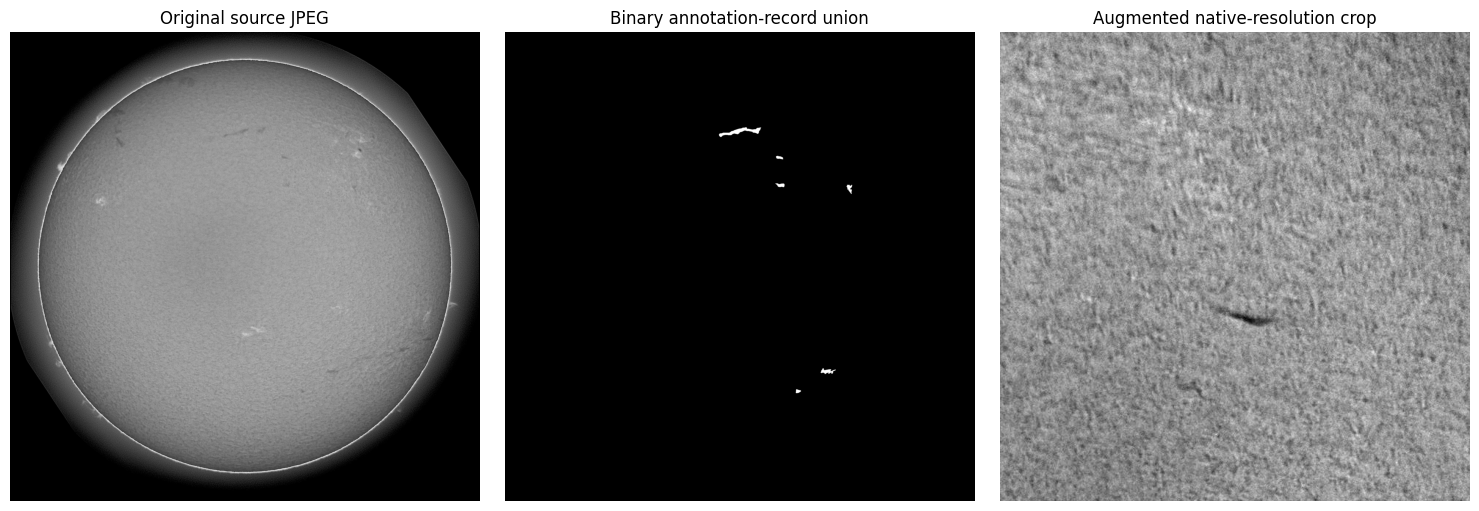

Sample image: (1, 640, 640) mask: (1, 640, 640) foreground pixels: 1048


In [ ]:
example = TRAIN_DATASET[0]
record = RECORDS_BY_FILE[TRAIN_NAMES[0]][0]
img = read_gray(str(TRAIN_PATHS[TRAIN_NAMES[0]]))
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(img, cmap="gray"); ax[0].set_title("Original source JPEG")
ax[1].imshow(mmap_mask(record["mask_path"]), cmap="gray"); ax[1].set_title("Binary annotation-record union")
ax[2].imshow(example["image"][0] * CFG.gray_std + CFG.gray_mean, cmap="gray")
ax[2].set_title("Augmented native-resolution crop")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()
print("Sample image:", tuple(example["image"].shape), "mask:", tuple(example["mask"].shape),
      "foreground pixels:", int(example["mask"].sum()))


## Cell 11 — Genuine DeepLabV3+ with pretrained ResNet50, ASPP and skip-connection decoder

In [ ]:
# Native PyTorch implementation; no segmentation_models_pytorch/timm dependency.
def conv_gn_relu(cin, cout, kernel=3, dilation=1):
    return nn.Sequential(
        nn.Conv2d(cin, cout, kernel, padding=((kernel-1)//2)*dilation,
                  dilation=dilation, bias=False),
        nn.GroupNorm(32, cout), nn.ReLU(inplace=True),
    )

class SeparableConv(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(cin, cin, 3, padding=1, groups=cin, bias=False),
            nn.Conv2d(cin, cout, 1, bias=False),
            nn.GroupNorm(32, cout), nn.ReLU(inplace=True),
        )
    def forward(self, x): return self.net(x)

class ASPP(nn.Module):
    def __init__(self, cin=2048, cout=256, rates=(12, 24, 36)):
        super().__init__()
        self.branches = nn.ModuleList([conv_gn_relu(cin, cout, 1)] +
                                      [conv_gn_relu(cin, cout, 3, r) for r in rates])
        self.pool = conv_gn_relu(cin, cout, 1)
        self.project = nn.Sequential(conv_gn_relu(cout * 5, cout, 1), nn.Dropout2d(0.1))
    def forward(self, x):
        size = x.shape[-2:]
        pooled = self.pool(F.adaptive_avg_pool2d(x, 1))
        pooled = F.interpolate(pooled, size=size, mode="bilinear", align_corners=False)
        return self.project(torch.cat([branch(x) for branch in self.branches] + [pooled], dim=1))

class DeepLabV3PlusBinary(nn.Module):
    def __init__(self, pretrained=True):
        super().__init__()
        weights = ResNet50_Weights.IMAGENET1K_V2 if pretrained else None
        encoder = resnet50(weights=weights, replace_stride_with_dilation=[False, True, True])
        old_stem = encoder.conv1
        gray_stem = nn.Conv2d(1, 64, 7, stride=2, padding=3, bias=False)
        with torch.no_grad():
            gray_stem.weight.copy_(old_stem.weight.sum(dim=1, keepdim=True) if pretrained
                                   else old_stem.weight.mean(dim=1, keepdim=True))
        encoder.conv1 = gray_stem
        self.encoder = encoder
        self.aspp = ASPP(2048, 256)
        # GroupNorm requires group count dividing 48; custom conv for low level.
        self.low_project = nn.Sequential(nn.Conv2d(256, 48, 1, bias=False),
                                         nn.GroupNorm(16, 48), nn.ReLU(inplace=True))
        self.decoder = nn.Sequential(SeparableConv(256 + 48, 256), SeparableConv(256, 256))
        self.head = nn.Conv2d(256, 1, 1)
        nn.init.normal_(self.head.weight, std=0.01)
        nn.init.constant_(self.head.bias, math.log(.02 / .98))
    def forward(self, x):
        input_shape = x.shape[-2:]
        e = self.encoder
        z = e.maxpool(e.relu(e.bn1(e.conv1(x))))
        low = e.layer1(z)              # stride 4: preserve local details
        high = e.layer4(e.layer3(e.layer2(low)))  # stride 8
        ctx = self.aspp(high)
        ctx = F.interpolate(ctx, size=low.shape[-2:], mode="bilinear", align_corners=False)
        z = self.decoder(torch.cat((ctx, self.low_project(low)), dim=1))
        z = self.head(z)
        return F.interpolate(z, size=input_shape, mode="bilinear", align_corners=False)

def freeze_encoder_bn(net):
    for m in net.encoder.modules():
        if isinstance(m, nn.modules.batchnorm._BatchNorm):
            m.eval()                 # freeze running statistics for small microbatches

def make_model(pretrained):
    try:
        model = DeepLabV3PlusBinary(pretrained=pretrained)
    except Exception as exc:
        if pretrained:
            raise RuntimeError("Could not load ImageNet ResNet50 V2 weights. Enable Colab Internet, "
                               "or set encoder_pretrained=False as a clearly documented ablation.") from exc
        raise
    if DEVICE.type == "cuda" and CFG.channels_last:
        model = model.to(memory_format=torch.channels_last)
    return model.to(DEVICE)

MODEL = make_model(CFG.encoder_pretrained and CFG.do_train and CFG.resume in ("none", "auto")
                   and not (RUN / "last.pt").exists())
freeze_encoder_bn(MODEL)
print("DeepLabV3+ / ResNet50 / output stride 8 / input 1 / output 1")
print("Trainable parameters:", sum(p.numel() for p in MODEL.parameters() if p.requires_grad))


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 240MB/s]


DeepLabV3+ / ResNet50 / output stride 8 / input 1 / output 1
Trainable parameters: 41247929


## Cell 12 — V2 BCE + FP-aware Tversky + edge loss (optional clDice ablation)

In [ ]:
def soft_erode(x):
    # 2D differentiable soft morphological erosion.
    return -F.max_pool2d(-x, 3, stride=1, padding=1)

def soft_dilate(x):
    return F.max_pool2d(x, 3, stride=1, padding=1)

def soft_skeleton(x, iterations=6):
    opened = soft_dilate(soft_erode(x))
    result = F.relu(x - opened)
    for _ in range(iterations):
        x = soft_erode(x)
        opened = soft_dilate(soft_erode(x))
        delta = F.relu(x - opened)
        result = result + F.relu(delta - result * delta)
    return result

class FilamentLossV2(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.register_buffer("pos_weight", torch.tensor([cfg.positive_bce_weight], dtype=torch.float32))
    def forward(self, logits, labels):
        x = logits.float()
        y = labels.float()
        if x.shape != y.shape or x.ndim != 4 or x.shape[1] != 1:
            raise ValueError("V2 loss expects matching [N,1,H,W] tensors")
        pixel_bce = F.binary_cross_entropy_with_logits(
            x, y, pos_weight=self.pos_weight.view(1,1,1,1), reduction="none")
        bce = pixel_bce.mean()
        p = torch.sigmoid(x)
        dims = (1, 2, 3)
        tp = (p * y).sum(dims)
        fp = (p * (1 - y)).sum(dims)
        fn = ((1 - p) * y).sum(dims)
        tversky = (1 - (tp + 1.0) / (tp + self.cfg.tversky_alpha_fp * fp
                                    + self.cfg.tversky_beta_fn * fn + 1.0)).mean()
        # Band of GT boundary pixels, including both sides; no fake crop-edge distance labels.
        dilated = F.max_pool2d(y, kernel_size=3, stride=1, padding=1)
        eroded = -F.max_pool2d(-y, kernel_size=3, stride=1, padding=1)
        edge = (dilated - eroded).clamp(0, 1)
        edge_bce = (pixel_bce * edge).sum() / edge.sum().clamp_min(1.0)
        if self.cfg.cldice_coefficient > 0:
            skel_p = soft_skeleton(p, self.cfg.cldice_iterations)
            skel_y = soft_skeleton(y, self.cfg.cldice_iterations)
            precision = ((skel_p * y).sum(dims) + 1) / (skel_p.sum(dims) + 1)
            sensitivity = ((skel_y * p).sum(dims) + 1) / (skel_y.sum(dims) + 1)
            cldice = (1 - (2 * precision * sensitivity + 1e-6) /
                      (precision + sensitivity + 1e-6)).mean()
        else:
            cldice = x.new_zeros(())
        total = (self.cfg.bce_coefficient * bce
                 + self.cfg.tversky_coefficient * tversky
                 + self.cfg.edge_coefficient * edge_bce
                 + self.cfg.cldice_coefficient * cldice)
        parts = {"bce": bce.detach(), "tversky": tversky.detach(),
                 "edge_bce": edge_bce.detach(), "cldice": cldice.detach(), "loss": total.detach()}
        return total, parts

CRITERION = FilamentLossV2(CFG).to(DEVICE)
print("V2 objective:", CFG.bce_coefficient, "BCE +", CFG.tversky_coefficient,
      "Tversky +", CFG.edge_coefficient, "EdgeBCE +", CFG.cldice_coefficient, "clDice")


V2 objective: 0.5 BCE + 1.0 Tversky + 0.2 EdgeBCE + 0.0 clDice


## Cell 13 — Exact instance PQ statistics, confident components, and efficient sparse COCO-RLE

In [ ]:
STAT_KEYS = ("sum_iou", "tp", "fp", "fn", "records", "ambiguous_gt", "ambiguous_pred")
def empty_stats():
    return {k: (0.0 if k == "sum_iou" else 0) for k in STAT_KEYS}
def add_stats(total, value):
    for k in STAT_KEYS: total[k] += value[k]
def summarize_stats(stats):
    denominator = stats["tp"] + .5 * (stats["fp"] + stats["fn"])
    return {**stats, "pq": float(stats["sum_iou"] / denominator) if denominator else 1.0,
            "sq": float(stats["sum_iou"] / stats["tp"]) if stats["tp"] else
                  (1.0 if denominator == 0 else 0.0),
            "rq": float(stats["tp"] / denominator) if denominator else 1.0}

def match_iou_matrix(iou):
    iou = np.asarray(iou, np.float64)
    qualified = np.where(iou > 0.5, iou, 0.0)
    # Prune nonmatching columns: Hungarian work scales with number of candidates.
    if qualified.size and np.any(qualified > 0):
        use_rows = np.flatnonzero((qualified > 0).any(axis=1))
        use_cols = np.flatnonzero((qualified > 0).any(axis=0))
        reduced = qualified[np.ix_(use_rows, use_cols)]
        rr, cc = linear_sum_assignment(reduced, maximize=True)
        matches = [float(reduced[r, c]) for r, c in zip(rr, cc) if reduced[r, c] > 0]
    else:
        matches = []
    count = len(matches)
    return {"sum_iou": float(sum(matches)), "tp": count,
            "fp": int(iou.shape[1] - count), "fn": int(iou.shape[0] - count), "records": 1,
            "ambiguous_gt": int(((qualified > 0).sum(axis=1) > 1).sum()),
            "ambiguous_pred": int(((qualified > 0).sum(axis=0) > 1).sum())}

def score_instances_coco(gt, predictions):
    original = [native_rle(r) for r in gt]
    predicted = [native_rle(r) for r in predictions]
    matrix = (mask_api.iou(original, predicted, [0] * len(predicted))
              if original and predicted else np.zeros((len(original), len(predicted))))
    return match_iou_matrix(matrix)

def label_components(prob, threshold, connectivity=8):
    if prob.ndim != 2 or not np.isfinite(prob).all():
        raise ValueError("Probability must be finite 2D array")
    structure = ndi.generate_binary_structure(2, 2 if connectivity == 8 else 1)
    labels, _ = ndi.label(prob >= threshold, structure)
    areas = np.bincount(labels.ravel())
    means = (np.bincount(labels.ravel(), weights=prob.ravel(), minlength=len(areas)) /
             np.maximum(areas, 1))
    return labels, areas, means

def get_gt_decoded(name):
    return [([decode_mask(rle) for rle in rec["instances"]],
             np.asarray([float(mask_api.area(native_rle(rle))) for rle in rec["instances"]]))
            for rec in RECORDS_BY_FILE[name]]

def compute_ious_for_components(labels, areas, decoded):
    # GT x component matrix; each GT mask is scanned only once per threshold.
    num_components = len(areas) - 1
    out = []
    for masks, gt_areas in decoded:
        ious = np.zeros((len(masks), num_components), np.float64)
        for row, (mask, area_gt) in enumerate(zip(masks, gt_areas)):
            intersection = np.bincount(labels[mask], minlength=len(areas))[1:]
            denominator = area_gt + areas[1:] - intersection
            ious[row] = np.divide(intersection, denominator, out=np.zeros(num_components),
                                   where=denominator > 0)
        out.append(ious)
    return out

def score_label_grid(areas, means, iou_matrices, settings):
    # settings: list of (minimum_area, minimum_mean_confidence)
    output = {tuple(setting): empty_stats() for setting in settings}
    for area, conf in settings:
        keep = (areas[1:] >= area) & (means[1:] >= conf)
        for iou in iou_matrices:
            add_stats(output[(area, conf)], match_iou_matrix(iou[:, keep]))
    return output

def sparse_component_rle(labels, label_id, slices):
    # Emit full-frame COCO-RLE from one component's tight bounding slice.
    # This avoids constructing 2048x2048 boolean masks for every instance.
    region = slices[label_id - 1]
    if region is None: raise ValueError(f"Missing component label {label_id}")
    (ys, xs) = region
    rows, cols = np.nonzero(labels[ys, xs] == label_id)
    if len(rows) == 0: raise ValueError("Empty predicted component")
    h, w = labels.shape
    positions = np.sort((cols + xs.start).astype(np.int64) * h + (rows + ys.start))
    boundaries = np.flatnonzero(np.diff(positions) != 1) + 1
    begins = np.r_[0, boundaries]
    ends = np.r_[boundaries, len(positions)]
    run_starts, run_ends = positions[begins], positions[ends - 1] + 1
    counts = [int(run_starts[0])]
    for idx in range(len(run_starts)):
        counts.append(int(run_ends[idx] - run_starts[idx]))
        if idx + 1 < len(run_starts):
            counts.append(int(run_starts[idx+1] - run_ends[idx]))
    counts.append(int(h*w - run_ends[-1]))
    if sum(counts) != h*w: raise AssertionError("Broken sparse RLE")
    compressed = mask_api.frPyObjects({"size": [h, w], "counts": counts}, h, w)
    rle = json_rle(compressed)
    if int(mask_api.area(native_rle(rle))) != len(positions):
        raise AssertionError("Sparse RLE area mismatch")
    return rle

def component_bank(probability, threshold, minimum_area, min_mean_confidence=0.0,
                   connectivity=8, return_labels=False):
    labels, areas, means = label_components(probability, threshold, connectivity)
    keep = np.flatnonzero((areas[1:] >= minimum_area) &
                          (means[1:] >= min_mean_confidence)) + 1
    if len(keep) > np.iinfo(np.uint16).max:
        raise ValueError("More than 65535 instances; cannot write uint16 instance PNG")
    slices = ndi.find_objects(labels)
    bank = [{"area": int(areas[i]), "mean_probability": float(means[i]),
             "rle": sparse_component_rle(labels, int(i), slices)} for i in keep]
    if not return_labels: return bank
    lut = np.zeros(len(areas), dtype=np.uint16)
    lut[keep] = np.arange(1, len(keep)+1, dtype=np.uint16)
    return bank, lut[labels]

def score_full_file(name, probability, threshold, min_area, min_conf):
    labels, areas, means = label_components(probability, threshold, CFG.connectivity)
    ious = compute_ious_for_components(labels, areas, get_gt_decoded(name))
    return score_label_grid(areas, means, ious, [(min_area, min_conf)])[(min_area, min_conf)]


## Cell 14 — Batched native-resolution tiling, optional real flip TTA, and GPU probability blending

In [ ]:
def tile_starts(length, tile, stride):
    if length <= tile: return [0]
    coords = list(range(0, length-tile+1, stride))
    if coords[-1] != length-tile: coords.append(length-tile)
    return coords

def transform_tensor(tensor, operation, inverse=False):
    if operation == "identity": return tensor
    if operation == "hflip": return torch.flip(tensor, dims=(-1,))
    if operation == "vflip": return torch.flip(tensor, dims=(-2,))
    if operation == "rot90": return torch.rot90(tensor, -1 if inverse else 1, dims=(-2,-1))
    raise ValueError(f"Unknown TTA transform: {operation}")

def prepare_inference_image(image, mode, cfg):
    if mode == "raw": return image
    if mode == "clahe":
        return cv2.createCLAHE(clipLimit=cfg.inference_clahe_clip,
                               tileGridSize=cfg.clahe_grid).apply(image)
    raise ValueError(f"Unknown mode: {mode}")

@torch.inference_mode()
def predict_full_image(net, image, cfg, mode="raw"):
    if image.dtype != np.uint8 or image.ndim != 2: raise ValueError("Expected uint8 grayscale HxW")
    net.eval()
    prepared = prepare_inference_image(image, mode, cfg)
    h, w = prepared.shape
    tile, stride = cfg.inference_tile, cfg.inference_stride
    hp, wp = max(h, tile), max(w, tile)
    padded = (np.pad(prepared, ((0, hp-h), (0, wp-w)), mode="reflect")
              if hp != h or wp != w else prepared)
    coordinates = [(y, x) for y in tile_starts(hp, tile, stride)
                   for x in tile_starts(wp, tile, stride)]
    window1d = torch.hann_window(tile, periodic=False, device=DEVICE, dtype=torch.float32)
    window = torch.outer(window1d, window1d).clamp_min_(0.05)
    acc = torch.zeros((hp, wp), dtype=torch.float32, device=DEVICE)
    weight = torch.zeros_like(acc)
    for start in range(0, len(coordinates), cfg.inference_batch):
        subset = coordinates[start:start + cfg.inference_batch]
        batch = np.stack([padded[y:y+tile, x:x+tile] for y, x in subset])
        x = torch.from_numpy(((batch.astype(np.float32) / 255.0 - cfg.gray_mean) / cfg.gray_std)[:, None])
        x = x.to(DEVICE, non_blocking=False)
        if DEVICE.type == "cuda" and cfg.channels_last:
            x = x.contiguous(memory_format=torch.channels_last)
        p = None
        for op in cfg.tta:
            with autocast_context(): logits = net(transform_tensor(x, op))
            if logits.shape != x.shape: raise RuntimeError("Binary decoder output does not match input")
            transformed = transform_tensor(logits.float().sigmoid(), op, inverse=True)
            p = transformed if p is None else (p + transformed)
        if p is None: raise ValueError("TTA operations empty")
        p = (p / len(cfg.tta))[:, 0]
        for (y, x0), patch in zip(subset, p):
            acc[y:y+tile, x0:x0+tile].add_(patch * window)
            weight[y:y+tile, x0:x0+tile].add_(window)
    if bool((weight <= 0).any().item()): raise RuntimeError("Tile coverage error")
    return (acc / weight).clamp_(0, 1)[:h, :w].cpu().numpy().astype(np.float32, copy=False)

print("Tiling", CFG.inference_tile, "/", CFG.inference_stride,
      "tiles per frame:", len(tile_starts(CFG.expected_shape[0], CFG.inference_tile, CFG.inference_stride))**2)


Tiling 640 / 512 tiles per frame: 16


## Cell 15 — Checkpoint EMA, fused optimizer, warmup-cosine scheduler, and local-then-Drive persistence

In [ ]:
class EMA:
    def __init__(self, model, decay):
        self.model = copy.deepcopy(model).eval()
        self.model.requires_grad_(False)
        self.decay, self.updates = decay, 0
    @torch.no_grad()
    def update(self, net):
        self.updates += 1
        ratio = min(self.decay, (1 + self.updates) / (10 + self.updates))
        dst = list(self.model.parameters())
        src = list(net.parameters())
        if hasattr(torch, "_foreach_lerp_"):
            torch._foreach_lerp_(dst, src, 1 - ratio)
        else:
            for a, b in zip(dst, src): a.lerp_(b, 1-ratio)
        for a, b in zip(self.model.buffers(), net.buffers()): a.copy_(b)

def make_optimizer(net, cfg):
    params = [
        {"params": list(net.encoder.parameters()), "lr": cfg.encoder_lr},
        {"params": list(net.aspp.parameters()) + list(net.low_project.parameters()) +
                   list(net.decoder.parameters()) + list(net.head.parameters()), "lr": cfg.decoder_lr},
    ]
    optkwargs = {"weight_decay": cfg.weight_decay}
    if DEVICE.type == "cuda" and cfg.use_fused_adamw:
        optkwargs["fused"] = True
    optimizer = torch.optim.AdamW(params, **optkwargs)
    steps_epoch = cfg.microbatches_per_epoch // cfg.accumulation
    warmup = max(1, cfg.warmup_epochs * steps_epoch)
    total = cfg.epochs * steps_epoch
    def schedule(step):
        if step < warmup: return .1 + .9 * (step + 1) / warmup
        fraction = min(1., (step - warmup) / max(1, total-warmup))
        return .05 + .95 * .5 * (1 + math.cos(math.pi * fraction))
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, schedule)
    scaler = torch.amp.GradScaler("cuda", enabled=(AMP_ENABLED and AMP_DTYPE == torch.float16))
    return optimizer, scheduler, scaler

def signature(cfg):
    config = asdict(cfg)
    for key in ("local_dataset_override", "run_dir", "v1_split_path", "split_csv", "resume",
                "do_train", "export_test", "save_probability_maps", "workers", "prefetch_factor",
                "evaluate_holdout"):
        config.pop(key, None)
    return object_hash({"impl": "sfsc-v2-deeplabv3plus-20261010", "config": config,
                        "annotation": ANN_SHA, "split": SPLIT_SHA})

RUN_SIGNATURE = signature(CFG)

def cpu_state_dict(net):
    return {k: v.detach().cpu().clone() for k, v in net.state_dict().items()}

def save_checkpoint_atomic(value, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temp_local = LOCAL_ROOT / (path.name + ".local.tmp")
    temp_dest = path.with_suffix(path.suffix + ".part")
    success = False
    try:
        torch.save(value, temp_local)
        shutil.copyfile(temp_local, temp_dest)
        if temp_dest.stat().st_size != temp_local.stat().st_size:
            raise OSError("Incomplete checkpoint copy")
        os.replace(temp_dest, path)
        success = True
    except OSError as exc:
        recovery = LOCAL_ROOT / (path.stem + "_recovery.pt")
        if temp_local.exists():
            shutil.copyfile(temp_local, recovery)
        raise OSError(f"Could not write checkpoint to Google Drive: {path}. "
                      f"A recovery copy may exist at {recovery}. Reconnect Drive first.") from exc
    finally:
        if success: temp_local.unlink(missing_ok=True)
        temp_dest.unlink(missing_ok=True)

LAST_PT, BEST_PT = RUN / "last.pt", RUN / "best.pt"
print("V2 config signature:", RUN_SIGNATURE)
print("Best checkpoint:", BEST_PT)


V2 config signature: fe8339a8050f8f75a83a3f6e6f708a72e04d27351a8ec137a8ca844a1b56ffab
Best checkpoint: /content/drive/MyDrive/SFSC2026/outputs/sfsc_deeplabv3plus_v2/best.pt


## Cell 16 — Development evaluator and probability-cache helpers

In [ ]:
def inference_recipe(cfg, mode):
    return {"mode": mode, "tile": cfg.inference_tile, "stride": cfg.inference_stride,
            "batch": cfg.inference_batch, "tta": list(cfg.tta), "mean": cfg.gray_mean,
            "std": cfg.gray_std, "clahe_clip": cfg.inference_clahe_clip,
            "clahe_grid": list(cfg.clahe_grid), "precision": str(AMP_DTYPE),
            "channels_last": cfg.channels_last}

def evaluate_model(net, names, cfg, threshold, area, confidence=0., mode="raw"):
    total, per_file = empty_stats(), []
    for name in tqdm(names, desc=f"Evaluate development PQ ({mode})", leave=False):
        p = predict_full_image(net, read_gray(str(TRAIN_PATHS[name])), cfg, mode)
        stats = score_full_file(name, p, threshold, area, confidence)
        add_stats(total, stats)
        per_file.append({"file_name": name, **stats})
    return summarize_stats(total), per_file

def cache_probabilities(net, names, cfg, mode, checkpoint_hash, scope="dev"):
    meta = {"checkpoint": checkpoint_hash, "annotation": ANN_SHA, "split": SPLIT_SHA,
            "inference": inference_recipe(cfg, mode), "scope": scope}
    location = LOCAL_CACHE / "probabilities" / object_hash(meta)[:20]
    location.mkdir(parents=True, exist_ok=True)
    write_json(location / "provenance.json", meta)
    paths = {}
    for name in tqdm(names, desc=f"Cache {scope} raw probabilities"):
        path = location / (Path(name).stem + ".npy")
        if not path.is_file():
            source = TRAIN_PATHS.get(name, TEST_PATHS.get(name))
            if source is None: raise ValueError(f"Unknown JPEG: {name}")
            p = predict_full_image(net, read_gray(str(source)), cfg, mode)
            save_npy_atomic(path, p)
        paths[name] = path
    return paths


## Cell 17 — Synthetic preflight tests: loss, model, tile reconstruction, sparse-RLE parity, and PQ scoring

In [ ]:
def runtime_tests():
    h, w = 63, 71
    m = np.zeros((h, w), np.uint8)
    m[8:19, 10:16] = 1
    rle = encode_mask(m)
    assert np.array_equal(decode_mask(rle), m > 0)
    assert summarize_stats(score_instances_coco([rle], [rle]))["pq"] == 1.0
    assert match_iou_matrix(np.array([[.5]]))["tp"] == 0
    assert match_iou_matrix(np.array([[.5001]]))["tp"] == 1
    synthetic = np.zeros((h, w), np.float32)
    synthetic[8:19, 10:16] = .95
    synthetic[35:42, 50:60] = .95
    labels, areas, means = label_components(synthetic, .5, 8)
    slots = ndi.find_objects(labels)
    for index in (1, 2):
        sparse = sparse_component_rle(labels, index, slots)
        assert np.array_equal(decode_mask(sparse), labels == index)
    # CPU/Colab: check optimized component IoU agrees with COCO reference under filters.
    synthetic_name = "__v2_synthetic__"
    RECORDS_BY_FILE[synthetic_name] = [{"instances": [rle]}]
    try:
        decoded = get_gt_decoded(synthetic_name)
        ious = compute_ious_for_components(labels, areas, decoded)
        for area in (1, 70):
            keep = np.flatnonzero((areas[1:] >= area) & (means[1:] >= .5)) + 1
            optimized = score_label_grid(areas, means, ious, [(area, .5)])[(area, .5)]
            reference = score_instances_coco([rle], [sparse_component_rle(labels, i, slots) for i in keep])
            for key in STAT_KEYS: assert np.isclose(optimized[key], reference[key]), (key, area)
    finally:
        del RECORDS_BY_FILE[synthetic_name]
    for raw in (np.zeros((32, 32), np.uint8), np.ones((32, 32), np.uint8), m[:32,:32]):
        logits = torch.zeros((1, 1) + raw.shape, device=DEVICE, requires_grad=True)
        target = torch.tensor(raw, device=DEVICE)[None,None]
        val, parts = CRITERION(logits, target)
        val.backward()
        assert bool(torch.isfinite(val).item()) and bool(torch.isfinite(logits.grad).all().item())
        assert torch.allclose(val.detach(), CFG.bce_coefficient*parts["bce"] +
                              CFG.tversky_coefficient*parts["tversky"] +
                              CFG.edge_coefficient*parts["edge_bce"] +
                              CFG.cldice_coefficient*parts["cldice"])
    # Tiny pointwise network: all tiles + TTA must reconstruct the same map.
    class IdentityNet(nn.Module):
        def forward(self, x): return x
    small = copy.deepcopy(CFG)
    small.inference_tile, small.inference_stride, small.inference_batch = 32, 24, 2
    small.tta = ("identity", "hflip", "vflip", "rot90")
    inp = (np.arange(59*67, dtype=np.uint32).reshape(59, 67) % 256).astype(np.uint8)
    actual = predict_full_image(IdentityNet().to(DEVICE), inp, small, "raw")
    expect = 1 / (1 + np.exp(-(inp.astype(np.float32)/255. - small.gray_mean)/small.gray_std))
    assert np.allclose(actual, expect, atol=2e-6)
    print("PASS: COCO RLE, global PQ, sparse component RLE, IoU parity, loss grads and tiled TTA.")

runtime_tests()


PASS: COCO RLE, global PQ, sparse component RLE, IoU parity, loss grads and tiled TTA.


## Cell 18 — GPU memory & data-loader preflight (fails early with actionable batch-size advice)

In [ ]:
if CFG.do_train:
    batch = next(iter(TRAIN_LOADER))
    assert tuple(batch["image"].shape) == (CFG.batch_size, 1, CFG.crop_size, CFG.crop_size)
    assert batch["mask"].dtype == torch.uint8
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()
    t0 = time.perf_counter()
    x = batch["image"].to(DEVICE, non_blocking=True)
    y = batch["mask"].to(DEVICE, non_blocking=True)
    if DEVICE.type == "cuda" and CFG.channels_last: x = x.contiguous(memory_format=torch.channels_last)
    try:
        MODEL.train(); freeze_encoder_bn(MODEL)
        with autocast_context(): logits = MODEL(x)
        loss, _ = CRITERION(logits, y)
        loss.backward()
        assert logits.shape == x.shape
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        print("Forward/backward batch seconds:", round(time.perf_counter()-t0, 3))
        if DEVICE.type == "cuda":
            print("Peak GPU allocated GiB:", round(torch.cuda.max_memory_allocated()/2**30, 2))
    except torch.cuda.OutOfMemoryError as exc:
        MODEL.zero_grad(set_to_none=True)
        torch.cuda.empty_cache()
        raise RuntimeError("L4 OOM on preflight: reduce CFG.batch_size 2→1; keep accumulation 4 or increase "
                           "it to 8 if you need the same effective batch. Restart and rerun.") from exc
    finally:
        MODEL.zero_grad(set_to_none=True)
        del batch, x, y
else:
    print("Training disabled; skipping batch preflight")


Forward/backward batch seconds: 19.691
Peak GPU allocated GiB: 2.42


## Cell 19 — Train with efficient GPU AMP, EMA, automatic resume and PQ-based checkpoint selection

In [19]:
# Important: changing V2 architecture, loss, crop size or training schedule requires a NEW run folder.
def train_v2(net, dataset, cfg):
    if DEVICE.type != "cuda": raise RuntimeError("Select Colab GPU for V2 training")
    if cfg.compile_model:
        raise ValueError("compile_model=True is not yet checkpoint-parity tested; keep False for V2 baseline")
    if cfg.resume == "auto":
        resume_path = LAST_PT if LAST_PT.exists() else None
        if resume_path is None and BEST_PT.exists():
            raise RuntimeError("best.pt exists but last.pt is missing. Recover last.pt or use a NEW run folder.")
    elif cfg.resume == "none":
        if BEST_PT.exists() or LAST_PT.exists():
            raise FileExistsError("Refusing to overwrite existing V2 checkpoints. Use another run_dir.")
        resume_path = None
    else:
        resume_path = Path(cfg.resume)
        if not resume_path.is_file(): raise FileNotFoundError(resume_path)
    optimizer, scheduler, scaler = make_optimizer(net, cfg)
    ema = EMA(net, cfg.ema_decay)
    history, best_pq, best_epoch, stale, start_epoch = [], -1., -1, 0, 0
    if resume_path is not None:
        print("Loading trusted V2 resume checkpoint:", resume_path)
        state = torch.load(resume_path, map_location="cpu", weights_only=False)
        if state["signature"] != RUN_SIGNATURE:
            raise ValueError("Resume signature mismatch; never combine different V2 experiments")
        net.load_state_dict(state["model"])
        ema.model.load_state_dict(state["ema"])
        ema.updates = int(state["ema_updates"])
        optimizer.load_state_dict(state["optimizer"])
        scheduler.load_state_dict(state["scheduler"])
        scaler.load_state_dict(state["scaler"])
        start_epoch = int(state["epoch"]) + 1
        history = state["history"]
        best_pq, best_epoch, stale = state["best_pq"], state["best_epoch"], state["stale"]
        if BEST_PT.exists() and hash_file(BEST_PT) != state["best_sha256"]:
            raise ValueError("Best checkpoint was modified after resume state was saved")
        if not BEST_PT.exists(): raise FileNotFoundError("Missing best.pt alongside last.pt")
        torch.set_rng_state(state["torch_rng"].cpu())
        if DEVICE.type == "cuda" and state.get("cuda_rng"):
            torch.cuda.set_rng_state_all([v.cpu() for v in state["cuda_rng"]])
        print("Resuming at epoch", start_epoch + 1, "best raw-dev PQ", best_pq)

    write_json(RUN / "v2_config.json", {"config": asdict(cfg), "signature": RUN_SIGNATURE,
                                           "split_sha256": SPLIT_SHA, "annotation_sha256": ANN_SHA,
                                           "torch": torch.__version__, "amp_dtype": str(AMP_DTYPE)})
    loader = TRAIN_LOADER if dataset is TRAIN_DATASET else make_train_loader(dataset, cfg)
    trainable_parameters = [p for p in net.parameters() if p.requires_grad]
    for epoch in range(start_epoch, cfg.epochs):
        time_start = time.perf_counter()
        dataset.epoch = epoch
        net.train(); freeze_encoder_bn(net)
        optimizer.zero_grad(set_to_none=True)
        totals = {k: torch.zeros((), dtype=torch.float32, device=DEVICE)
                  for k in ("loss", "bce", "tversky", "edge_bce", "cldice")}
        wait_s, skipped = 0., 0
        it = iter(loader)
        bar = tqdm(range(len(loader)), desc=f"Epoch {epoch+1}/{cfg.epochs}")
        for step in bar:
            wait_start = time.perf_counter()
            batch = next(it)
            wait_s += time.perf_counter() - wait_start
            x = batch["image"].to(DEVICE, non_blocking=True)
            y = batch["mask"].to(DEVICE, non_blocking=True)
            if cfg.channels_last: x = x.contiguous(memory_format=torch.channels_last)
            with autocast_context(): logits = net(x)
            loss, parts = CRITERION(logits, y)
            if ((step+1) % cfg.finite_check_every == 0 or step+1 == len(loader)):
                if not bool(torch.isfinite(loss).item()):
                    raise FloatingPointError(f"NaN/Inf loss at epoch {epoch+1}, step {step+1}")
            scaler.scale(loss / cfg.accumulation).backward()
            with torch.no_grad():
                for key in totals: totals[key].add_(parts[key])
            if (step+1) % cfg.accumulation == 0:
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(trainable_parameters, max_norm=1.0, foreach=True)
                prev_scale = scaler.get_scale()
                scaler.step(optimizer)
                scaler.update()
                if scaler.get_scale() >= prev_scale:
                    scheduler.step()
                    ema.update(net)
                else:
                    skipped += 1
                optimizer.zero_grad(set_to_none=True)
            if (step+1) % cfg.log_every == 0:
                bar.set_postfix(loss=f"{totals['loss'].item()/(step+1):.4f}")
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        row = {"epoch": epoch+1, **{k: v.item()/len(loader) for k, v in totals.items()},
               "train_seconds": round(time.perf_counter()-time_start, 2),
               "cpu_wait_seconds": round(wait_s, 2),
               "lr_encoder": optimizer.param_groups[0]["lr"], "skipped_updates": skipped,
               "peak_gpu_gib": round(torch.cuda.max_memory_allocated()/2**30, 3)}
        due = (epoch == 0 or (epoch+1) % cfg.eval_every == 0 or epoch+1 == cfg.epochs)
        new_best = False
        if due:
            eval_names = FILES["dev"][:cfg.validation_limit] if cfg.validation_limit else FILES["dev"]
            stats, per_file = evaluate_model(ema.model, eval_names, cfg, cfg.selection_threshold,
                                              cfg.selection_minimum_area, cfg.selection_mean_confidence)
            row.update({"dev_"+key: value for key, value in stats.items()})
            print("Fixed-recipe development:", {k: stats[k] for k in ("pq", "sq", "rq", "tp", "fp", "fn")})
            if stats["pq"] > best_pq:
                new_best = True
                best_pq, best_epoch, stale = stats["pq"], epoch+1, 0
                save_checkpoint_atomic({"state_dict": cpu_state_dict(ema.model), "epoch": best_epoch,
                                        "dev_pq": best_pq, "signature": RUN_SIGNATURE,
                                        "split_sha256": SPLIT_SHA, "annotation_sha256": ANN_SHA}, BEST_PT)
                write_json(RUN / "best_fixed_recipe_dev.json", {"summary": stats, "per_file": per_file})
            else:
                stale += 1
        row["epoch_seconds"] = round(time.perf_counter() - time_start, 2)
        history.append(row)
        pd.DataFrame(history).to_csv(RUN / "training_history.csv", index=False)
        save_due = (new_best or (epoch+1) % cfg.save_resume_every == 0 or epoch+1 == cfg.epochs
                    or stale >= cfg.patience_evaluations)
        if save_due:
            save_checkpoint_atomic({"model": net.state_dict(), "ema": ema.model.state_dict(),
                                    "ema_updates": ema.updates, "optimizer": optimizer.state_dict(),
                                    "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(),
                                    "epoch": epoch, "history": history, "best_pq": best_pq,
                                    "best_epoch": best_epoch, "stale": stale, "signature": RUN_SIGNATURE,
                                    "best_sha256": hash_file(BEST_PT),
                                    "torch_rng": torch.get_rng_state(),
                                    "cuda_rng": torch.cuda.get_rng_state_all()}, LAST_PT)
        print(f"Epoch {epoch+1:03d} | training {row['train_seconds']:.1f}s | total {row['epoch_seconds']:.1f}s "
              f"| CPU wait ~{row['cpu_wait_seconds']:.1f}s | best dev PQ {best_pq:.5f} @ {best_epoch}")
        if stale >= cfg.patience_evaluations:
            print("Early stopping after", stale, "validation evaluations without improvement")
            break
    return history

if CFG.do_train:
    HISTORY = train_v2(MODEL, TRAIN_DATASET, CFG)
else:
    if not BEST_PT.exists(): raise FileNotFoundError("do_train=False needs V2 best.pt")
    HISTORY = (pd.read_csv(RUN / "training_history.csv").to_dict("records")
               if (RUN / "training_history.csv").exists() else [])


Epoch 1/64:   0%|          | 0/192 [00:00<?, ?it/s]

Evaluate development PQ (raw):   0%|          | 0/106 [00:00<?, ?it/s]

Fixed-recipe development: {'pq': 0.03465927100891019, 'sq': 0.587392121527197, 'rq': 0.05900533857825232, 'tp': 105, 'fp': 2406, 'fn': 943}
Epoch 001 | training 26.7s | total 103.5s | CPU wait ~0.1s | best dev PQ 0.03466 @ 1


Epoch 2/64:   0%|          | 0/192 [00:00<?, ?it/s]

Epoch 002 | training 27.1s | total 27.1s | CPU wait ~0.1s | best dev PQ 0.03466 @ 1


Epoch 3/64:   0%|          | 0/192 [00:00<?, ?it/s]

... (135 outputs left out)

Epoch 063 | training 26.8s | total 26.8s | CPU wait ~0.2s | best dev PQ 0.31895 @ 52


Epoch 64/64:   0%|          | 0/192 [00:00<?, ?it/s]

Evaluate development PQ (raw):   0%|          | 0/106 [00:00<?, ?it/s]

Fixed-recipe development: {'pq': 0.31452546272089427, 'sq': 0.666096097722745, 'rq': 0.4721923214926444, 'tp': 658, 'fp': 1081, 'fn': 390}
Epoch 064 | training 27.0s | total 100.8s | CPU wait ~0.1s | best dev PQ 0.31895 @ 52


## Cell 20 — Training curves and restore exact best EMA model

Best epoch 52 fixed-recipe development PQ 0.3189496935702019


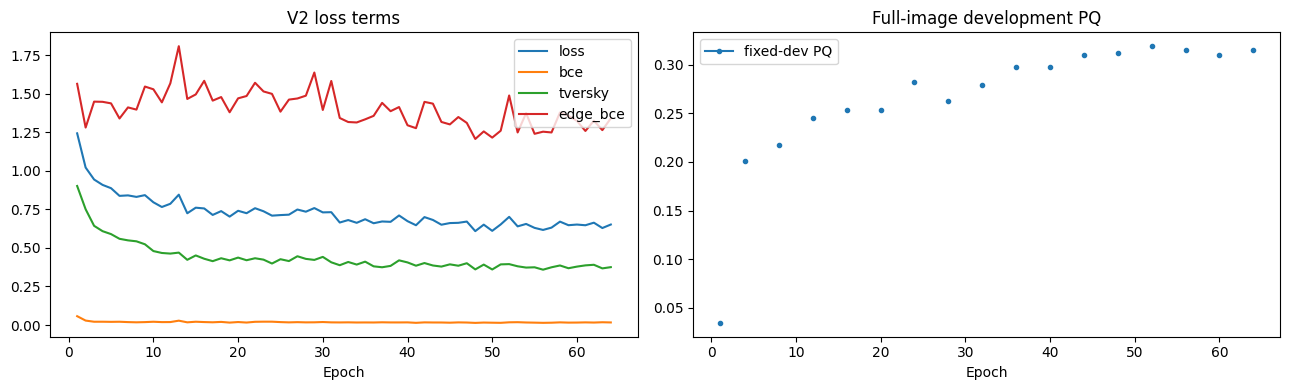

In [20]:
BEST = torch.load(BEST_PT, map_location="cpu", weights_only=True)
if BEST["signature"] != RUN_SIGNATURE: raise ValueError("Best checkpoint does not match V2 configuration")
BEST_SHA = hash_file(BEST_PT)
MODEL.load_state_dict(BEST["state_dict"], strict=True)
MODEL.to(DEVICE).eval()
print("Best epoch", BEST["epoch"], "fixed-recipe development PQ", BEST["dev_pq"])

if HISTORY:
    hist = pd.DataFrame(HISTORY)
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    for name in ("loss", "bce", "tversky", "edge_bce"):
        ax[0].plot(hist["epoch"], hist[name], label=name)
    ax[0].legend(); ax[0].set_title("V2 loss terms"); ax[0].set_xlabel("Epoch")
    if "dev_pq" in hist.columns:
        ax[1].plot(hist["epoch"], hist["dev_pq"], marker=".", label="fixed-dev PQ")
    ax[1].set_title("Full-image development PQ"); ax[1].set_xlabel("Epoch")
    ax[1].legend(); plt.tight_layout(); plt.show()


## Cell 21 — Calibrate threshold, area, and mean probability on DEV ONLY (no redundant RLE encoding)

In [21]:
CALIBRATION_CONFIG = {"checkpoint_sha256": BEST_SHA, "split_sha256": SPLIT_SHA,
                      "thresholds": list(CFG.thresholds), "areas": list(CFG.minimum_areas),
                      "confidences": list(CFG.minimum_mean_confidences),
                      "modes": list(CFG.inference_modes),
                      "inference": [inference_recipe(CFG, mode) for mode in CFG.inference_modes],
                      "validation_limit": CFG.validation_limit}
CALIBRATION_HASH = object_hash(CALIBRATION_CONFIG)
CALIBRATION_PATH = RUN / "calibration_v2.json"

if CALIBRATION_PATH.exists():
    previously = json.loads(CALIBRATION_PATH.read_text())
    if previously.get("hash") == CALIBRATION_HASH:
        CALIBRATION_ROWS = previously["rows"]
        print("Reused frozen calibration for the same checkpoint and inference settings")
    else:
        raise ValueError("Calibration file differs from current settings. Use a NEW V2 experiment folder.")
else:
    CALIBRATION_ROWS = []
    settings = [(int(a), float(c)) for a in CFG.minimum_areas for c in CFG.minimum_mean_confidences]
    for mode in CFG.inference_modes:
        names = FILES["dev"][:CFG.validation_limit] if CFG.validation_limit else FILES["dev"]
        paths = cache_probabilities(MODEL, names, CFG, mode, BEST_SHA, "dev")
        totals = {(float(t), a, c): empty_stats() for t in CFG.thresholds for a, c in settings}
        for name, path in tqdm(paths.items(), desc=f"PQ calibration on development: {mode}"):
            probability = np.load(path, mmap_mode="r", allow_pickle=False)
            if probability.shape != tuple(CFG.expected_shape): raise ValueError("Bad cached probability dimensions")
            decoded = get_gt_decoded(name)  # per image, not per threshold or area
            for threshold in CFG.thresholds:
                labels, areas, means = label_components(probability, threshold, CFG.connectivity)
                ious = compute_ious_for_components(labels, areas, decoded)
                local = score_label_grid(areas, means, ious, settings)
                for (area, conf), stats in local.items():
                    add_stats(totals[(float(threshold), area, conf)], stats)
        for (threshold, area, conf), stats in totals.items():
            CALIBRATION_ROWS.append({"mode": mode, "threshold": threshold,
                                     "minimum_area": area, "mean_confidence": conf,
                                     **summarize_stats(stats)})
    write_json(CALIBRATION_PATH, {"hash": CALIBRATION_HASH,
                                   "settings": CALIBRATION_CONFIG, "rows": CALIBRATION_ROWS})

CALIBRATION = pd.DataFrame(CALIBRATION_ROWS)
CALIBRATION.to_csv(RUN / "calibration_v2.csv", index=False)
WINNER = min(CALIBRATION_ROWS, key=lambda d: (-d["pq"], d["mode"] != "raw",
                                                  abs(d["threshold"]-.7), abs(math.log2(d["minimum_area"]/128)),
                                                  d["mean_confidence"]))
print(CALIBRATION.sort_values("pq", ascending=False).head(15).to_string(index=False))
print("Selected dev-only recipe:", WINNER)
if CFG.validation_limit: warnings.warn("WARNING: calibration used only a validation SUBSET, not reportable full development PQ")


Cache dev raw probabilities:   0%|          | 0/106 [00:00<?, ?it/s]

PQ calibration on development: raw:   0%|          | 0/106 [00:00<?, ?it/s]

mode  threshold  minimum_area  mean_confidence    sum_iou  tp  fp  fn  records  ambiguous_gt  ambiguous_pred       pq       sq       rq
 raw       0.55            96             0.85 403.244426 595 366 453      152             0               0 0.401438 0.677722 0.592334
 raw       0.55           128             0.85 403.244426 595 366 453      152             0               0 0.401438 0.677722 0.592334
 raw       0.55            64             0.85 403.244426 595 366 453      152             0               0 0.401438 0.677722 0.592334
 raw       0.55           192             0.85 403.244426 595 366 453      152             0               0 0.401438 0.677722 0.592334
 raw       0.55            32             0.85 403.244426 595 366 453      152             0               0 0.401438 0.677722 0.592334
 raw       0.55           256             0.85 402.515949 594 364 454      152             0               0 0.401312 0.677636 0.592223
 raw       0.55           384             0.85 3

## Cell 22 — Freeze V2 recipe and evaluate the already-observed holdout only after calibration

In [22]:
RECIPE = {"implementation": "sfsc-deeplabv3plus-v2", "architecture": "DeepLabV3+ ResNet50 stride8 gray1->binary1",
          "checkpoint_sha256": BEST_SHA, "best_epoch": int(BEST["epoch"]),
          "annotation_sha256": ANN_SHA, "split_sha256": SPLIT_SHA,
          "evaluation": "global additive PQ, strict IoU>0.5, max-IoU bipartite assignment",
          "inference": inference_recipe(CFG, WINNER["mode"]),
          "threshold": float(WINNER["threshold"]), "minimum_area": int(WINNER["minimum_area"]),
          "mean_confidence": float(WINNER["mean_confidence"]), "connectivity": CFG.connectivity,
          "development": {k: WINNER[k] for k in ("pq", "sq", "rq", "tp", "fp", "fn")},
          "calibration_hash": CALIBRATION_HASH,
          "objective": {k: getattr(CFG, k) for k in ("positive_bce_weight", "tversky_alpha_fp",
                        "tversky_beta_fn", "bce_coefficient", "tversky_coefficient", "edge_coefficient",
                        "cldice_coefficient")},
          "warning": "V1 holdout was previously inspected, so no longer a pristine blind set"}
RECIPE_SHA = object_hash(RECIPE)
FROZEN_PATH = RUN / "frozen_recipe_v2.json"
if FROZEN_PATH.exists():
    previous = json.loads(FROZEN_PATH.read_text())
    if previous["sha256"] != RECIPE_SHA:
        raise RuntimeError("A different V2 recipe was already frozen in this run directory")
else:
    write_json(FROZEN_PATH, {"sha256": RECIPE_SHA, "recipe": RECIPE})

def assert_frozen_recipe():
    if hash_file(BEST_PT) != RECIPE["checkpoint_sha256"]:
        raise ValueError("Best checkpoint changed since calibration")
    if inference_recipe(CFG, RECIPE["inference"]["mode"]) != RECIPE["inference"]:
        raise ValueError("Inference parameters changed after threshold calibration")
    if SPLIT_SHA != RECIPE["split_sha256"] or ANN_SHA != RECIPE["annotation_sha256"]:
        raise ValueError("Validation split or annotations changed")
    # Prevent exporting in-memory weights from a different training epoch.
    loaded = torch.load(BEST_PT, map_location="cpu", weights_only=True)
    MODEL.load_state_dict(loaded["state_dict"], strict=True)
    MODEL.to(DEVICE).eval()

print("Frozen V2 recipe:", RECIPE_SHA)
HOLDOUT_REPORT = None
if CFG.evaluate_holdout:
    assert_frozen_recipe()
    report_path = RUN / "holdout_report_v2.json"
    if report_path.exists():
        HOLDOUT_REPORT = json.loads(report_path.read_text())
        if HOLDOUT_REPORT["recipe_sha256"] != RECIPE_SHA:
            raise ValueError("Holdout already evaluated under another recipe")
    else:
        summary, per_image = evaluate_model(MODEL, FILES["holdout"], CFG,
                                             RECIPE["threshold"], RECIPE["minimum_area"],
                                             RECIPE["mean_confidence"], RECIPE["inference"]["mode"])
        HOLDOUT_REPORT = {"recipe_sha256": RECIPE_SHA, "summary": summary,
                          "per_file": per_image, "holdout_was_previously_seen_in_v1": True}
        write_json(report_path, HOLDOUT_REPORT)
    print("Holdout (not truly blind):", HOLDOUT_REPORT["summary"])
else:
    print("Holdout disabled; final export does not require holdout labels")


Frozen V2 recipe: 5f74f112210bb9ddd71162139d8c8aa476d755f2640e8496c76c224d96fd74a6


Evaluate development PQ (raw):   0%|          | 0/103 [00:00<?, ?it/s]

Holdout (not truly blind): {'sum_iou': 545.5862328900354, 'tp': 789, 'fp': 398, 'fn': 559, 'records': 174, 'ambiguous_gt': 0, 'ambiguous_pred': 0, 'pq': 0.43044278728996876, 'sq': 0.6914907894677255, 'rq': 0.6224852071005917}


## Cell 23 — Final test inference and V1-compatible compressed COCO-RLE submission CSV

In [23]:
LOCAL_EXPORT = LOCAL_ROOT / "test_export"
EXPORT = RUN / "test_export"
LOCAL_EXPORT.mkdir(parents=True, exist_ok=True)
EXPORT.mkdir(parents=True, exist_ok=True)
for folder in ("binary_masks", "instance_masks"):
    (LOCAL_EXPORT / folder).mkdir(parents=True, exist_ok=True)
if CFG.save_probability_maps:
    (LOCAL_EXPORT / "probabilities").mkdir(parents=True, exist_ok=True)

SUBMISSION_PATH = EXPORT / "submission.csv"
EXPORT_RECORDS_PATH = EXPORT / "processed_images.json"
PROCESSED = []

if CFG.export_test:
    assert_frozen_recipe()
    rows = []
    for name, path in tqdm(sorted(TEST_PATHS.items()), desc="V2 test full-resolution inference"):
        image = read_gray(str(path))
        if image.shape != tuple(CFG.expected_shape):
            raise ValueError(f"Wrong test JPEG shape: {name}: {image.shape}")
        probability = predict_full_image(MODEL, image, CFG, RECIPE["inference"]["mode"])
        bank, labels = component_bank(probability, RECIPE["threshold"], RECIPE["minimum_area"],
                                      RECIPE["mean_confidence"], RECIPE["connectivity"],
                                      return_labels=True)
        stem = Path(name).stem
        Image.fromarray((labels > 0).astype(np.uint8) * 255).save(
            LOCAL_EXPORT / "binary_masks" / f"{stem}.png")
        Image.fromarray(labels.astype(np.uint16)).save(
            LOCAL_EXPORT / "instance_masks" / f"{stem}.png")
        if CFG.save_probability_maps:
            save_npy_atomic(LOCAL_EXPORT / "probabilities" / f"{stem}.npy", probability)
        for index, instance in enumerate(bank, start=1):
            rows.append({"filament_id": f"{stem}_{index}",
                         "segmentation_rle": instance["rle"]["counts"]})
        PROCESSED.append({"file_name": name, "filament_count": len(bank)})
    submission = pd.DataFrame(rows, columns=["filament_id", "segmentation_rle"])
    local_csv = LOCAL_EXPORT / "submission.csv"
    submission.to_csv(local_csv, index=False)
    copy_atomic(local_csv, SUBMISSION_PATH)
    write_json(EXPORT_RECORDS_PATH, {"recipe_sha256": RECIPE_SHA,
                                     "images": PROCESSED, "instances": len(rows)})
    print("Submission:", SUBMISSION_PATH)
    print("Predicted instances:", len(rows), "Images with zero predictions:",
          sum(r["filament_count"] == 0 for r in PROCESSED))
    if not len(rows): warnings.warn("Empty submission. Review training and calibration.")
else:
    print("export_test=False: skipping test inference")


V2 test full-resolution inference:   0%|          | 0/180 [00:00<?, ?it/s]

Submission: /content/drive/MyDrive/SFSC2026/outputs/sfsc_deeplabv3plus_v2/test_export/submission.csv
Predicted instances: 1138 Images with zero predictions: 2


## Cell 24 — Audit every exported instance RLE against saved 16-bit instance masks

In [24]:
if CFG.export_test:
    table = pd.read_csv(SUBMISSION_PATH, dtype=str, keep_default_na=False)
    if list(table.columns) != ["filament_id", "segmentation_rle"]:
        raise ValueError("Submission CSV schema mismatch")
    if table.filament_id.duplicated().any():
        raise ValueError("Duplicate filament IDs")
    by_stem = defaultdict(list)
    for row in table.itertuples(index=False):
        stem, suffix = row.filament_id.rsplit("_", 1)
        if not suffix.isdigit() or int(suffix) < 1: raise ValueError("Bad filament ID suffix")
        by_stem[stem].append((int(suffix), row.segmentation_rle))
    for processed in tqdm(PROCESSED, desc="Audit COCO compressed RLE CSV"):
        stem = Path(processed["file_name"]).stem
        png_path = LOCAL_EXPORT / "instance_masks" / f"{stem}.png"
        gt_labels = np.asarray(Image.open(png_path)).astype(np.uint16)
        rebuilt = np.zeros(tuple(CFG.expected_shape), dtype=np.uint16)
        found = by_stem.get(stem, [])
        if len(found) != processed["filament_count"]:
            raise AssertionError(f"Wrong number of exported instances: {stem}")
        for suffix, counts in found:
            m = decode_mask({"size": list(CFG.expected_shape), "counts": counts})
            if not m.any() or np.any(rebuilt[m]):
                raise AssertionError(f"Empty/overlapping predicted instance: {stem}_{suffix}")
            rebuilt[m] = suffix
        if not np.array_equal(rebuilt, gt_labels):
            raise AssertionError(f"RLE/instance PNG disagreement: {stem}")
        binary = np.asarray(Image.open(LOCAL_EXPORT / "binary_masks" / f"{stem}.png")) > 0
        if not np.array_equal(binary, rebuilt > 0):
            raise AssertionError(f"Binary PNG disagrees: {stem}")
    report = {"passed": True, "images": len(PROCESSED), "instances": len(table),
              "submission_sha256": hash_file(SUBMISSION_PATH), "recipe_sha256": RECIPE_SHA}
    write_json(EXPORT / "serialization_audit.json", report)
    print("All instance masks match compressed COCO-RLE submission exactly")

    # Persist all PNGs efficiently as a single ZIP (no thousands of Drive writes).
    local_archive = LOCAL_ROOT / "test_masks_v2.zip"
    with zipfile.ZipFile(local_archive, "w", compression=zipfile.ZIP_DEFLATED,
                         compresslevel=2) as archive:
        for f in tqdm(sorted(LOCAL_EXPORT.rglob("*")), desc="Package PNGs"):
            if f.is_file(): archive.write(f, f.relative_to(LOCAL_EXPORT))
    copy_atomic(local_archive, EXPORT / "test_masks_v2.zip")
    print("PNG/mask archive:", EXPORT / "test_masks_v2.zip")
else:
    print("Skipping export audit")


Audit COCO compressed RLE CSV:   0%|          | 0/180 [00:00<?, ?it/s]

All instance masks match compressed COCO-RLE submission exactly


Package PNGs:   0%|          | 0/363 [00:00<?, ?it/s]

PNG/mask archive: /content/drive/MyDrive/SFSC2026/outputs/sfsc_deeplabv3plus_v2/test_export/test_masks_v2.zip


## Cell 25 — Reusable single-image inference function (no retraining)

In [25]:
@torch.inference_mode()
def segment_image_v2(path, save_binary_to=None):
    assert_frozen_recipe()
    image = read_gray(str(path))
    if image.shape != tuple(CFG.expected_shape):
        raise ValueError("Please provide an original 2048x2048 grayscale solar JPEG")
    probability = predict_full_image(MODEL, image, CFG, RECIPE["inference"]["mode"])
    bank, labels = component_bank(probability, RECIPE["threshold"], RECIPE["minimum_area"],
                                  RECIPE["mean_confidence"], RECIPE["connectivity"], True)
    binary = (labels > 0).astype(np.uint8)
    if save_binary_to:
        output = Path(save_binary_to); output.parent.mkdir(parents=True, exist_ok=True)
        Image.fromarray(binary * 255).save(output)
    return {"binary_mask": binary, "instance_labels": labels, "instances": bank,
            "filament_count": len(bank), "probability": probability}

print("Reusable: segment_image_v2('/path/to/2048x2048.jpeg')")


Reusable: segment_image_v2('/path/to/2048x2048.jpeg')


## Cell 26 — Persist environment, comparisons, and run provenance

In [26]:
import subprocess, sys
freeze = subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True)
(RUN / "environment_v2.txt").write_text(freeze.stdout)
manifest = {"algorithm": "DeepLabV3Plus-ResNet50 V2", "seed": CFG.seed,
            "recipe_sha256": RECIPE_SHA, "best_checkpoint_sha256": BEST_SHA,
            "best_epoch": int(BEST["epoch"]), "calibrated_dev_pq": float(WINNER["pq"]),
            "calibrated_dev_sq": float(WINNER["sq"]), "calibrated_dev_rq": float(WINNER["rq"]),
            "holdout_pq": (float(HOLDOUT_REPORT["summary"]["pq"]) if HOLDOUT_REPORT else None),
            "split_sha256": SPLIT_SHA, "reused_v1_split": REUSED_V1_SPLIT,
            "annotation_sha256": ANN_SHA, "GPU": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU",
            "amp_dtype": str(AMP_DTYPE) if AMP_ENABLED else "off",
            "python": platform.python_version(), "torch": torch.__version__,
            "torchvision": torchvision.__version__, "opencv": cv2.__version__,
            "submission": str(SUBMISSION_PATH) if CFG.export_test else None,
            "submission_sha256": hash_file(SUBMISSION_PATH) if CFG.export_test else None,
            "note": "V1 holdout was previously inspected. No V2 PQ improvement is certified without fair comparison."}
write_json(RUN / "manifest_v2.json", manifest)
print(json.dumps(manifest, indent=2))
print("Run artifacts stored at:", RUN)


{
  "algorithm": "DeepLabV3Plus-ResNet50 V2",
  "seed": 20261010,
  "recipe_sha256": "5f74f112210bb9ddd71162139d8c8aa476d755f2640e8496c76c224d96fd74a6",
  "best_checkpoint_sha256": "0c56fd22a134d107f9fcdc2de2e891f26376a544514e586ed657fbd37ea24a9c",
  "best_epoch": 52,
  "calibrated_dev_pq": 0.40143795517089087,
  "calibrated_dev_sq": 0.6777217243179158,
  "calibrated_dev_rq": 0.5923344947735192,
  "holdout_pq": 0.43044278728996876,
  "split_sha256": "4b8d9570b883cf8a1982f336d5422be781ebc917aa8353c67f2acb55609c5c25",
  "reused_v1_split": true,
  "annotation_sha256": "5da9e92b5a1a1947fd5d57adb6688269625c48ec1ef884daf2a01618c9ed54a1",
  "GPU": "NVIDIA L4",
  "amp_dtype": "torch.bfloat16",
  "python": "3.13.15",
  "torch": "2.11.0+cu130",
  "torchvision": "0.26.0+cu130",
  "opencv": "4.14.0",
  "submission": "/content/drive/MyDrive/SFSC2026/outputs/sfsc_deeplabv3plus_v2/test_export/submission.csv",
  "submission_sha256": "5a11cc02ac673f993c1fe522ba25e487ee6280790047ab6035b4b2c7682437f9",
 

## Architecture, metric and reproducibility notes

- **Model architecture:** adapted from Chen et al., *Encoder-Decoder with Atrous Separable Convolution for Semantic Image Segmentation* (DeepLabV3+), [paper](https://arxiv.org/abs/1802.02611). Encoder initialized using torchvision ImageNet ResNet50 weights. Custom decoder uses ASPP + low-level features + depthwise-separable blocks; pretrained V1 21-class DeepLab weights **cannot** be loaded into this different architecture.
- **Tversky objective:** FP penalty (`alpha=0.65`) is stronger than FN penalty (`beta=0.35`) to address V1's high false-positive rate. This adjusts pixel loss; it does not mathematically guarantee instance PQ improvement. See [Tversky loss](https://arxiv.org/abs/1706.05721).
- **clDice:** separately switchable (`cldice_coefficient > 0`) for *tubular* topology supervision, but defaults off to avoid inadvertently joining separate objects. See [clDice](https://arxiv.org/abs/2003.07311).
- **COCO format:** preserves **annotation record** distinction (different human annotators can give different filament masks for one source JPEG), **all 4 categories collapse to one binary foreground**, holds split by unique original JPEG and date/hash, and uses compressed COCO counts for `segmentation_rle`. CSV columns remain `filament_id,segmentation_rle` as in V1.
- **PQ:** global sum of matched instance IoUs divided by `TP+0.5*FP+0.5*FN`, with one-to-one maximum-IoU Hungarian matching and strict `IoU>0.5`. `SQ` and `RQ` are also printed. Match graph ambiguities are tracked. Verify edge cases and final submission with the competition's current official scorer before relying on leaderboard equivalence.
- **Confidence filter:** `mean probability over a connected component >= threshold`, tuned on dev, not on holdout. Threshold/area/confidence grid and inference geometry are part of frozen recipe.
- **L4 resources:** local JPEGs, mmap binary masks, persistent DataLoader worker prefetch, channels-last convolution, BF16 preference on supported GPUs, fused AdamW, GPU tile accumulation. `nvidia-smi` utilization may still fluctuate with data loading and checkpointing; see logged `cpu_wait_seconds` and `peak_gpu_gib`. GPU efficiency is not assumed without benchmarking on your runtime.
- **Resource costs:** Colab SSD is temporary; weight/checkpoint files persist on Drive. If local storage is tight, do not stage uncompressed targets on Drive while training; configure a larger local runtime or an alternate mounted SSD. The notebook fails if required paths are missing rather than silently using synthetic data.
- **Comparisons:** V1 best development PQ from the prior notebook was ~0.3175 after calibration; holdout ~0.3550. Those results are only directly comparable if **split and scorer definitions match**. V2 is untrained until you execute this notebook; these are not expected V2 outcomes.